# Oxygen Optode Pipeline: Aanderaa

This notebook is the workspace for writing the code that processes dissolved oxygen measured on glider optodes, which will be integrated into the toolbox being developed at NOC within the GLIDERS - RISC project. Only working with Aanderaa optodes for now. A separate notebook will be created for other optodes (e.g., SeaBird). 

Start: 20251031

By: Elise Droste (elise.droste@noc.ac.uk)



***
# Resources

The processing steps are based on previous work in the DO optode community, as well as how it is done for BGC Argo. This is a list of links to consulted works and code: 

<b>Manuscripts</b>
- Bittig et al. (2018): https://www.frontiersin.org/journals/marine-science/articles/10.3389/fmars.2017.00429/full 
- Bittig & Körtzinger (2017)


<b>SOPs</b>
- Ocean Gliders SOPs: https://oceangliderscommunity.github.io/Oxygen_SOP/README.html
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/ \ https://archimer.ifremer.fr/doc/00348/45915/56281.pdf
- IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual: https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf : Woo, L.M. and Gourcuff, C. (2023). Delayed Mode QA/QC Best Practice Manual Version 3.1 Integrated Marine Observing System. DOI: 10.26198/5c997b5fdc9bd (https://dx.doi.org/10.26198/5c997b5fdc9bd)

  DOI: https://dx.doi.org/10.26198/5c997b5fdc9bd
- Thierry et al. (2025), Argo Quality Control Manual: https://archimer.ifremer.fr/doc/00354/46542/
- Thierry et al. (2025a), Processing Argo Oxygen data at the DAC level: https://dx.doi.org/10.13155/39795 

<b>Code - Public</b>
- Ocean Gliders O2 SOP GitHub: https://github.com/OceanGlidersCommunity/Oxygen_SOP
- UEA Seagldier Toolbox: https://bitbucket.org/bastienqueste/uea-seaglider-toolbox/src/toolbox/
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/
- GEOMAR Glider Toolbox: https://git.geomar.de/open-source/geomar_glider_toolbox

<b>Code - Private</b>
- Filipa Carvalho: matlab files. 
- Charlotte: TBA

***
# Processing roadmap

A visualisation of the oxygen optode processing pipeline can be found here: 

https://www.figma.com/board/7bYMOu1zaj6fzAU1Ar2YQ8/Glider_DO_Optode_Pipeline?node-id=0-1&p=f&t=vkOw6Ba9V9yyuACe-0 

Where this fits in the overall pipeline can be found here: 

https://www.figma.com/board/9adA0ffM4Rr0zxeM6tzCvk/Standard-Glider-Processing?node-id=0-1&p=f&t=JqsBqmDLPoukYXvy-0 


***
# Packages

## conda environment

<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
<s> Add notes on yml file and add link on how to install it.</s>
</div>

## Python packages

In [372]:
import numpy as np
import xarray as xr
import pandas as pd
import datetime
import gsw
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from IPython.core.interactiveshell import InteractiveShell 
InteractiveShell.ast_node_interactivity = "all" # allow multiple outputs from 1 cell


## Modules

<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
Once functions have been tested, move all into a Class and save as module.
</div>

***
# Settings and calibration sheets

## Import calibration sheet

Calibration coefficients are saved in a subfolder, called _calibration_sheets_, which contains the data in py files that can be imported here. 

Add calibration data from the manufacturer in the appropriate calibration sheet, saved in dir _calibration_sheets_. 

In [222]:
from calibration_sheets import calibration_sheet_aa4831 as cal_sheet_aa

In [223]:
cal_sheet_aa.SVUFoilCoef0

0.00267915

## Import settings

Set settings in _optode_pipeline_settings.py_, found in _settings_. 

In [224]:
import importlib # To re-load modules after changes are made 

In [358]:
importlib.reload(optode_pipeline_settings)

<module 'settings.optode_pipeline_settings' from '/Users/elidro/ED_Science/RISC_DO_Optode/RISC_DO_Optode_scripts/settings/optode_pipeline_settings.py'>

In [226]:
from settings import optode_pipeline_settings

In [227]:
optode_pipeline_settings.Pcoef1

In [269]:
optode_pipeline_settings.uncal_phase_doxy

'UNCAL_PHASE_DOXY'

***
# General functions

Check if instance is array-like. 

In [229]:
def is_array_like(obj):
    return isinstance(obj, (np.ndarray, xr.DataArray, pd.Series, list, tuple))

Run data through a low-pass filter. <font color=orange> Code currently used in geometric alignment step, but I haven't yet finished coding that step! </font> 

In [230]:
from scipy.signal import butter, filtfilt

In [231]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

***
# Data

Code is tested on data from the BioCarbon project. The data imported here is the output of the toolbox pipeline in the format in which it will be passed onto the optode pipeline. 

IDs of gliders: 
- Churchill 647
- Doombar 648
- Nelson ... 


<s> Data imported here are data previously exported from the prototype toolbox pipeline in August 2025. </s>

Data imported here are data run through the most up to date pipeline by Dan (20251202): 

In [232]:
%%bash

cd ../RISC_DO_Optode_rawdata/

ls 

pwd

Cabot_645_R_20250926.nc
Nelson_646_processed_20251126.nc
profiled_data_exported
/Users/elidro/ED_Science/RISC_DO_Optode/RISC_DO_Optode_rawdata


In [276]:
fdir = "../RISC_DO_Optode_rawdata//"
fname = "Nelson_646_processed_20251126.nc"
ds = xr.open_dataset(fdir + fname)

In [277]:
# ds.instrument # attribute containing list of instruments on the glider # no longer part of exported ds

In [278]:
ds

<xarray.Dataset> Size: 6GB
Dimensions:                                             (
                                                         N_MEASUREMENTS: 11331883,
                                                         N_PARAM: 30)
Dimensions without coordinates: N_MEASUREMENTS, N_PARAM
Data variables: (12/112)
    OXYCOPVR                                            (N_MEASUREMENTS) float32 45MB ...
    PLATFORM_TYPE                                       <U1 4B ...
    WATER_VELOC_FINAL_V_QC                              (N_MEASUREMENTS) int64 91MB ...
    CHLA_QC                                             (N_MEASUREMENTS) int64 91MB ...
    SENSOR_RADIOMETERS_459                              float64 8B ...
    SENSOR_RADIOMETERS_1611                             float64 8B ...
    ...                                                  ...
    CONS_TEMP                                           (N_MEASUREMENTS) float64 91MB ...
    CONS_TEMP_QC                                        (N_MEASUREMENTS) int64 91MB ...
    DENSITY                                             (N_MEASUREMENTS) float64 91MB ...
    DENSITY_QC                                          (N_MEASUREMENTS) int64 91MB ...
    CHLA_ADJUSTED                                       (N_MEASUREMENTS) float32 45MB ...
    CHLA_ADJUSTED_QC                                    (N_MEASUREMENTS) int64 91MB ...

Instrument attribute does not contain information about the manufacturer of the optode, but we know it is Aanderaa. 

Both Churchill and Doombar have <font color=lightblue>Aanderaa 4831</font>. I think Nelson has 3830! 



Manually set the optode type in the settings: 

<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
- [ ] Find a way to log the optode type, which is info required to make decisions along the processing tree
- [ ] Optode type in cal sheets is 4831, but the data is what I'd expect for 3830.. i.e. BPHASE and DPHASE. 4831 would have TCPHASE/TPHASE and TC1/2RPHASE... 
</div>

In [279]:
optode_pipeline_settings.sensor_type = "aa3830" # Unsure! I thought it was 4831, but that doesn't match what I'd expect from the variable names.. 

Check which optode-relevant variables have values in the dataset. 

In [280]:
optode_var_list = [  'DPHASE_DOXY',
                     'MOLAR_DOXY',
                     'TPHASE_DOXY',
                     "TCPHASE_DOXY", 
                     "CALPHASE_DOXY", 
                     "BPHASE_DOXY", 
                     'TEMP_DOXY',
                     'OXYSAT_DOXY',
                     'DPHASE_DOXY_QC',
                     'MOLAR_DOXY_QC',
                     'TPHASE_DOXY_QC',
                     'TEMP_DOXY_QC',
                     'OXYSAT_DOXY_QC', 
                      "CALPHASE_DOXY_QC", 
                     "TCPHASE_DOXY_QC", 
                     "BPHASE_DOXY_QC"]

In [281]:
print("Optode variables with only NaNs (True) or with data (False): ")
for var_name in optode_var_list:
    if var_name in ds.data_vars: 
        print(var_name, ds[var_name].isnull().all().item())
    else:
        print(var_name, " not found in variable list. ")

Optode variables with only NaNs (True) or with data (False): 
DPHASE_DOXY False
MOLAR_DOXY False
TPHASE_DOXY  not found in variable list. 
TCPHASE_DOXY  not found in variable list. 
CALPHASE_DOXY  not found in variable list. 
BPHASE_DOXY False
TEMP_DOXY  not found in variable list. 
OXYSAT_DOXY False
DPHASE_DOXY_QC False
MOLAR_DOXY_QC False
TPHASE_DOXY_QC  not found in variable list. 
TEMP_DOXY_QC  not found in variable list. 
OXYSAT_DOXY_QC False
CALPHASE_DOXY_QC  not found in variable list. 
TCPHASE_DOXY_QC  not found in variable list. 
BPHASE_DOXY_QC False


We have data:
- <b>BPHASE_DOXY</b>: Phase shift in blue excitatino light. Unit = degrees. <font color=pink> This will be the starting point of our calculations. </font>
- <b>DPHASE_DOXY</b>: calibrated phase measurement. Unit = degrees. <font color=pink> We re-calculate this ourselves (DPHASE = BPHASE). </font>
- <b>MOLAR_DOXY</b>: DO (dissolved oxygen concentration at zero pressure and in fresh water or at a reference salinity). Unit = umol L-1. These values are calculated by the instrument using manufacturer settings, but does not include a pressure correction on the phase shift. <font color=pink> We re-calculate this ourselves. </font>
- <b>OXYSAT_DOXY</b>: Oxygen saturation (percentage). Calculated using MOLAR_DOXY. <font color=pink> We re-calculate this ourselves. </font>

<font color=orange> <b>TEMP_DOXY</b>: Optode temperature measurements. Unit = degrees Celsius. Not found in dataset, but needed in calculations. </font> 

QC flag contains 0 and 9's only: 

In [282]:
np.unique(ds.BPHASE_DOXY_QC)
np.unique(ds.OXYSAT_DOXY_QC)
np.unique(ds.DPHASE_DOXY_QC)
np.unique(ds.MOLAR_DOXY_QC)

array([0, 9])

array([0, 9])

array([0, 9])

array([0, 9])

***
# Find starting phase shift [READY]

<img src=markdown_pngs/optode_IMOS.png width="500"/>
[Optode optical design (Aanderaa, 2007; copied from Woo & Gourcurr, 2023 - IMOS)]


Aanderaa optodes measure a blue light and a red light excitation. The results of the blue and red phase shifts are used to calculate an uncalibrated phase shift, which will then be used to determine the calibrated phase shift: 


RED/BLUE &rarr; UNCALIBRATED PHASE SHIFT &rarr; (UNCALIBRATED PHASE SHIFT with pressure correction) &rarr; CALIBRATED PHASE SHIFT 


The naming of all of these phase shifts differs for different optode types!! Fun. Fun. Our aim here is to find which phase shift data are included in the dataset (for blue/red, uncalibrated, and calibrated phase shifts), and use the lowest level data we can find to calculate the rest, overwriting any higher level data that might already exist. To make things easier and more streamlined, we will refer and re-name where necessary the uncalibrated phase shift to UNCAL_PHASE_DOXY and calibrated phase shift to CALPHASE_DOXY. 

The next sections help us find which uncalibrated and calibrated phase shift data are available in the dataset. 

## Find uncalibrated phase shift (UNCAL_PHASE)

The blue/red and uncalibrated phase shifts appear in Aanderaa datasets, like so: 

<b>Aanderaa 3830 </b>

The uncalibrated phase (UNCAL_PHASE, i.e., uncalibrated for temperature) is the difference between the excitation measured from the blue (BPHASE) and red (RPHASE) light: 

$$UNCAL\_PHASE\_DOXY = BPHASE\_DOXY - RPHASE\_DOXY$$

However, RPHASE is often not used, so 

$$UNCAL\_PHASE\_DOXY = BPHASE\_DOXY$$

Thierry et al. (2025a): For 3830 optodes, UNCAL_Phase = BPhase.  

For Argo, they call uncalibrated phase PHASE, but this is too confusing, so I'm calling it UNCAL_PHASE_DOXY

<b>Aanderaa 4330</b>

The uncalibrated phase (TCPHASE) is the difference between the excitation measured from the blue (C1RPHASE) and red (C2RPHASE) light: 

$$TCPHASE\_DOXY = C1RPHASE - C2RPHASE$$

Thierry et al. (2025a): For 4330 optodes, Uncalibrated phase = TCPhase, named as TPHASE in Argo nomenclature. 

$$UNCAL\_PHASE\_DOXY = TCPHASE\_DOXY = TPHASE\_DOXY$$


--- 

<font color=pink>So, for Aanderaa3830, we need either BPHASE or UNCAL_PHASE to start with. For Aanderaa4330 we need either both C1RPHASE and C2RPHASE or TCPHASE to start with. </font>

---

Dataset might contain optode phase shift data at different "stages" of calculation, e.g., BPHASE_DOXY, UNCAL_PHASE_DOXY, DPHASE_DOXY, etc. 
Here run through data variables within the dataset and try to find the available uncalibrated optode phase shift data in this order: 

Aanderaa 3830:
1. BPHASE_DOXY and RPHASE_DOXY (uncalibrated) - RPHASE_DOXY often not used. 
2. UNCAL_PHASE_DOXY (uncalibrated)

Aanderaa 4330, 4835, and 4831: 
1. C1RPHASE and C2RPHASE
2. TCPHASE_DOXY (uncalibrated)
3. TPHASE_DOXY (uncalibrated) = C1RPHASE (blue) - C2RPHASE (red). This is the same as TCPHASE_DOXY! But TPHASE is the naming by Argo. 

---

<font color=pink> Side note: PHASE variable in dataset is the behaviour of the glider at sea, it has nothing to do with the optode. </font>  

Continue pipeline with the <i>lowest level phase shift</i> available. If that's blue/red phase, calculate the uncalibrated phase shift first. Then continue with a pressure correction on the uncalibrated phase shift (UNCAL_PHASE_PCORR), followed by converting it to a calibrated phase shift (CALPHASE_DOXY). If the calibrated phase shift is teh lowest level phase shift available, the pressure correction on the phase shift cannot be performed. We will then simply use the calibrated phase shift as given and continue to calculating the molar concentration. 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Include TPHASE! Which is uncal phase??? 
- [x] Lower priority: Add what the other variables are that we might find of other Aandereaa optodes, e.g. TPHASE and CALPHASE.
- [x] <s>Consider using a varying variable to accommodate different names for uncalibrated and calibrated phase shifts.</s> Done.
</div>

In [283]:
def find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find uncalibrated optode phase shift data in dataset. Applicable to Aanderaa 3830 optodes. 
    """
    
    uncal_phase_found = ""
    raw_phase_names = ["BPHASE_DOXY", "UNCAL_PHASE_DOXY"]

    for phase_optode in raw_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                if phase_optode == "BPHASE_DOXY": # if BPHASE, calculate CAL_PHASE
                    if "UNCAL_PHASE_DOXY" in ds.data_vars: # replace existing UNCAL_PHASE
                        ds["UNCAL_PHASE_DOXY"].values = ds[phase_optode].values # replaces values of array only, but keeps attributes of original array
                        print("UNCAL_PHASE_DOXY determined from: ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    else: # Create new UNCAL_PHASE variable based on BPHASE
                        ds["UNCAL_PHASE_DOXY"] = ds[phase_optode] # this keeps the attributes of the original PHASE array
                        # ds.assign(UNCAL_PHASE = ds.BPHASE) # this does not keep the attributes of the original BPHASE array
                        print("UNCAL_PHASE_DOXY determined from: ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
                    
                elif phase_optode == "UNCAL_PHASE_DOXY": 
                    print("UNCAL_PHASE_DOXY found and contains values. Continue with UNCAL_PHASE. ")
                    uncal_phase_found = phase_optode
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
    
                else:
                    uncal_phase_found = None

        else: 
            uncal_phase_found = None
        
    if uncal_phase_found == None: 
        print("No uncalibrated phase shift found. ")

    return uncal_phase_found
                   
    

In [284]:
def find_uncalibrated_phase_optode_aa4330(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find uncalibrated optode phase shift data in dataset. Applicable to Aanderaa 4330 optodes. 
    Change uncal_phase_doxy in settings according to lowest level of phase shift data found. 
    """
    
    uncal_phase_found = ""
    raw_phase_names = ["C1RPHASE", "C2RPHASE", "TCPHASE_DOXY", "TPHASE_DOXY"]

    for phase_optode in raw_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                if phase_optode == "C1RPHASE": # if C1RPHASE, find C2RPHASE
                    if "C2RPHASE" not in ds.data_vars: 
                        print("C1RPHASE exists but C2RPHASE does not. Cannot calculate UNCAL_PHASE_DOXY. ")
                    else: 
                        if bool(ds["C2RPHASE"].isnull().all()): 
                            print("C1RPHASE exists, but C2RPHASE contains only NaNs. Cannot calculate UNCAL_PHASE_DOXY. ")
                        else: # calculate uncal_phase = c1rphase - c2rphase
                            ds["UNCAL_PHASE_DOXY"] = ds["C1RPHASE"] - ds["C2RPHASE"]
                            print("UNCAL_PHASE_DOXY calculated from C1RPHASE and C2RPHASE")
                            uncal_phase_found = "UNCAL_PHASE_DOXY"
                            optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                            break # get out of loop

                elif phase_optode == "C2RPHASE": # if C2RPHASE, find C1RPHASE
                    if "C1RPHASE" not in ds.data_vars: 
                        print("C2RPHASE exists but C1RPHASE does not. Cannot calculate UNCAL_PHASE_DOXY. ")
                    else: 
                        if bool(ds["C1RPHASE"].isnull().all()): 
                            print("C2RPHASE exists, but C1RPHASE contains only NaNs. Cannot calculate UNCAL_PHASE_DOXY. ")
                        else: # calculate uncal_phase = c1rphase - c2rphase
                            ds["UNCAL_PHASE_DOXY"] = ds["C1RPHASE"] - ds["C2RPHASE"]
                            print("UNCAL_PHASE_DOXY calculated from C1RPHASE and C2RPHASE")
                            uncal_phase_found = "UNCAL_PHASE_DOXY"
                            optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                            break # get out of loop
                        
                elif phase_optode == "TCPHASE_DOXY": 
                    ds["UNCAL_PHASE_DOXY"] = ds["TCPHASE_DOXY"]
                    print("TCPHASE_DOXY exists. Renamed to UNCAL_PHASE_DOXY.")
                    uncal_phase_found = "UNCAL_PHASE_DOXY"
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop

                elif phase_optode == "TPHASE_DOXY": 
                    ds["UNCAL_PHASE_DOXY"] = ds["TPHASE_DOXY"]
                    print("TPHASE_DOXY exists. Renamed to UNCAL_PHASE_DOXY.")
                    uncal_phase_found = "UNCAL_PHASE_DOXY"
                    optode_pipeline_settings.uncal_phase_doxy = "UNCAL_PHASE_DOXY" # set the uncalibrated phase shift variable 
                    break # get out of loop
                    
                else:
                    uncal_phase_found = None

        else: 
            uncal_phase_found = None
        
    if uncal_phase_found == None: 
        print(phase_optode, " not found in data variables. ")

    return uncal_phase_found
    

<div class="alert alert-block alert-success">
STEP: Check if blue/red and/or uncalibrated phase shift data exist in dataset:
</div>

In [285]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings)

UNCAL_PHASE_DOXY determined from:  BPHASE_DOXY .


'BPHASE_DOXY'

## Find calibrated phase shift (CALPHASE_DOXY)

If none of the uncalibrated phase shift data is included in the dataset, we need to look whether the calibrated phase shift data is available instead. 

These are the possible variable names for calibrated phase shift for all Aanderaa optodes:
1. DPHASE_DOXY (calibrated)
2. CALPHASE_DOXY (calibrated)

Note! If no uncalibrated phase shift data are available, then the pressure correction on the phase shift (next step) cannot be applied. 

In [286]:
def find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find calibrated optode phase shift data in dataset. Can be applied to both Aanderaa 3830 and 4330 optodes. 
    """
    
    cal_phase_found = ""
    cal_phase_names = ["DPHASE_DOXY", "CALPHASE_DOXY"]

    for phase_optode in cal_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                print(phase_optode, " found. ")
                ds["CALPHASE_DOXY"] = ds[phase_optode] # copy the calibrated phase shift and name it CALPHASE_DOXY for ongoing consistency
                cal_phase_found = phase_optode
                optode_pipeline_settings.calphase_doxy = "CALPHASE_DOXY" # set the calibrated phase shift variable 
                break # get out of loop
        else: 
            print("No calibrated phase shifts found. ")
            cal_phase_found = None
    
    if cal_phase_found == None: 
        print("No calibrated phase shift found. ")

    return cal_phase_found

<div class="alert alert-block alert-success">
STEP: Check if calibrated phase shift data (DPHASE_DOXY or CALPHASE_DOXY) exist in dataset:
</div>

In [287]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)

DPHASE_DOXY  found. 


'DPHASE_DOXY'

## Find phase shift (combined)

The function below just combines the functions above and spits out the lowest level phase shift data found to use in subsequent calculations. 

In [288]:
def find_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings): 
    """
    Find which red/blue, uncalibrated, and calibrated phase shift data exist in the Aanderaa optode dataset. 
    """
    
    all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
    all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)
    
    if len(all_optode_phases_list) == 0: # If nothing has been found 
        print("No variables names containing PHASE found. Check naming conventions and dataset. ")

    else: 
        # Check if uncalibrated phase shift data are present
        if optode_pipeline_settings.sensor_type in ["aa4330", "aa4835", "aa4831"]: 
            uncal_phase_found = find_uncalibrated_phase_optode_aa4330(ds, all_optode_phases_list, optode_pipeline_settings)
        elif optode_pipeline_settings.sensor_type in ["aa3830", "aa3835", "aa3930", "aa3975", "aa4130", "aa4175"]: 
            uncal_phase_found = find_uncalibrated_phase_optode_aa3830(ds, all_optode_phases_list, optode_pipeline_settings)
        else: 
            print("Aanderaa sensor type not included in this pipeline. Uncalibrated phase shift data not found. ")

        print(uncal_phase_found)
        if isinstance(uncal_phase_found, str): # if  uncalibrated phase shift data are present
            print("Uncalibrated phase shift found! Continue pipeline with ", uncal_phase_found, ". Next step: pressure correction. ")
            print("Settings updated for uncal_phase_doxy: ", optode_pipeline_settings.uncal_phase_doxy)
            
        else: # if uncalibrated phase shift data are not present, check for calibrated phase shift data
            cal_phase_found = find_calibrated_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)
            
            if isinstance(cal_phase_found, str): 
                print("No uncalibrated phase shifts found, but found calibrated phase shift: ", cal_phase_found, ". Continue with this but skip pressure correction on phase shift.")
                print("Settings updated for calphase_doxy: ", optode_pipeline_settings.calphase_doxy)
            else: 
                print("No uncalibrated or calibrated phase shifts found. Check data variables. ")

    print("Check: uncalibrated phase shift (if used for next steps) is ", optode_pipeline_settings.uncal_phase_doxy, ".")
    print("Check: calibrated phase shift (if used for next steps) is ", optode_pipeline_settings.calphase_doxy, ".")


<div class="alert alert-block alert-success">
STEP: Check if/which uncalibrated or calibrated phase shift data exist in dataset:
</div>

In [289]:
find_phase_optode_aa(ds, all_optode_phases_list, optode_pipeline_settings)


UNCAL_PHASE_DOXY determined from:  BPHASE_DOXY .
BPHASE_DOXY
Uncalibrated phase shift found! Continue pipeline with  BPHASE_DOXY . Next step: pressure correction. 
Settings updated for uncal_phase_doxy:  UNCAL_PHASE_DOXY
Check: uncalibrated phase shift (if used for next steps) is  UNCAL_PHASE_DOXY .
Check: calibrated phase shift (if used for next steps) is  CALPHASE_DOXY .


## Finding optode temperature [READY]

The optode also measures temperature: TEMP_DOXY. We will use these temperature measurements in some of the processing steps, depending on the optode type and version. 

Sometimes voltage of the thermistor is available. If so, we will use this to determine the temperature in degrees Celsius. 

In [290]:
def temp_doxy_voltage_to_degC_aa(TEMP_VOLTAGE_DOXY, cal_sheet_aa):
    """
    Convert thermistor voltage of oxygen optode to degrees Celsius using manufacturer coefficients. 
    Applies to Aanderaa 3830 and 4330. 

    Source: Thierry et al. (2025a). Processing Argo Oxygen data at the DAC level: https://dx.doi.org/10.13155/39795 

    ARGS:
        TEMP_VOLTAGE_DOXY: array-like
            Thermistor voltage in volts. 
        cal_sheet_aa: 
            Calibration sheet with manufacturer calibration coefficients. 

    RETURN:
        TEMP_DOXY: array-like
            Optode temperature in degrees Celsius. 
    """
    T0 = cal_sheet_aa.TempCoef0
    T1 = cal_sheet_aa.TempCoef1
    T2 = cal_sheet_aa.TempCoef2
    T3 = cal_sheet_aa.TempCoef3
    T4 = cal_sheet_aa.TempCoef4
    T5 = cal_sheet_aa.TempCoef5

    TEMP_DOXY = T0 + (T1*TEMP_VOLTAGE_DOXY) + (T2*TEMP_VOLTAGE_DOXY**2) + (T3*TEMP_VOLTAGE_DOXY**3) + (T4*TEMP_VOLTAGE_DOXY**4) + (T5*TEMP_VOLTAGE_DOXY**5)
    

    return TEMP_DOXY

In [291]:
def check_for_temp_doxy(ds, cal_sheet_aa): 
    """
    Check whether TEMP_DOXY and TEMP_VOLTAGE_DOXY exist in the dataset (and contain data). 
    If TEMP_VOLTAGE_DOXY exists, calculate TEMP_DOXY using the manufacturer calibration coefficients. 
    This can override existing TEMP_DOXY data. 
    """

    temp_doxy_exist = "no"
    if "TEMP_DOXY" in ds.data_vars: 
        if ds["TEMP_DOXY"].isnull.all(): 
            print("TEMP_DOXY found in data variables, but containst no data.")
        else: 
            print("TEMP_DOXY found in data variables.")
            temp_doxy_exist = "yes"
    else: 
        print("TEMP_DOXY not found in data variables.")
    
    if "TEMP_VOLTAGE_DOXY" in ds.data_vars: 
        if ds.TEMP_VOLTAGE_DOXY.isnull.all(): 
            print("TEMP_VOLTAGE_DOXY found in data variables, but contains no data. ")
            if temp_doxy_exist == "yes": 
                print("No problem, just using TEMP_DOXY for further calculations. ")
        else:
            
            if temp_doxy_exist == "yes": 
                ds.TEMP_DOXY = temp_doxy_voltage_to_degC_aa3830(TEMP_VOLTAGE_DOXY, cal_sheet_aa)
                print("TEMP_VOLTAGE_DOXY found in data variables. Existing TEMP_DOXY has been overridden with newly calculated TEMP_DOXY.")
            else: 
                ds["TEMP_DOXY"] = temp_doxy_voltage_to_degC_aa3830(TEMP_VOLTAGE_DOXY, cal_sheet_aa)
                print("TEMP_VOLTAGE_DOXY found in data variables. New TEMP_DOXY has been calculated.")
    else: 
        if temp_doxy_exist == "no": 
            print("Neither TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in data variables. Check dataset and naming conventions.")
        else: 
            print("TEMP_VOLTAGE_DOXY not found, but will use TEMP_DOXY for further calculations.")

<div class="alert alert-block alert-success">
STEP: Check if TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in dataset:
</div>

In [292]:
check_for_temp_doxy(ds, cal_sheet_aa)

TEMP_DOXY not found in data variables.
Neither TEMP_DOXY or TEMP_VOLTAGE_DOXY are found in data variables. Check dataset and naming conventions.


<div class="alert alert-block alert-warning">

TEMP_DOXY is not available in the dataset. Create a fake TEMP_DOXY based on CTD temperature (TEMP) for now.  

<b>To do: </b> 

- [ ] Replace temporary TEMP_DOXY with actual TEMP_DOXY
</div>

In [293]:
ds = ds.set_coords("TIME").swap_dims({"N_MEASUREMENTS": "TIME"}) # make time a coordinate and swap dimensions ie make dimension time
optode_meas_times = ds.TIME.where(~ds.BPHASE_DOXY.isnull(), drop = True) # find times when optode measurements were made 
temp_interp_onto_optode = ds.TEMP.interp(TIME = optode_meas_times) # interpolate TEMP onto these exact times
ds["TEMP_DOXY"] = temp_interp_onto_optode # copy interpolated CTD temperature measurements and pretend they're the optode's measurements 

ds = ds.swap_dims({"TIME": "N_MEASUREMENTS"}) # swap back


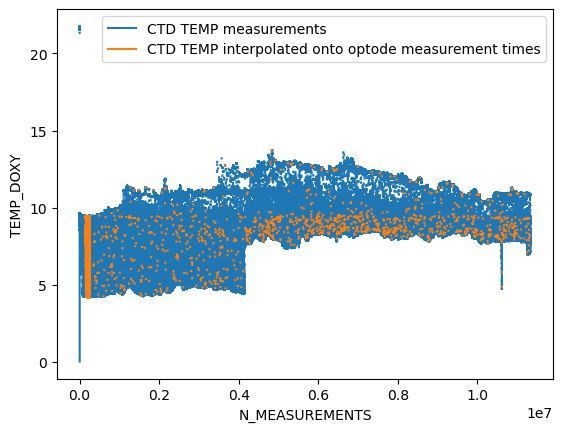

In [294]:
ds["TEMP"].plot(label = "CTD TEMP measurements")
ds["TEMP_DOXY"].plot( label = "CTD TEMP interpolated onto optode measurement times")
plt.legend();

***
# Geometrically align phase shift to CTD data [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input:  </b>
    
- geo_time_lag

<b>Optional input:  </b>

- distance between optode and CTD on glider
- glider dive rate
- glider pitch
</div>



We require CTD data for the next processing steps. However, since the CTD and optode sensors are not located in the same space on the glider, there's a time lag between the two. So we need to shift CTD data to align with the optode in space and in time, i.e., geometrically. 

<img src=markdown_pngs/glider_geo_shift.png width="500"/>
[Glider orientation during descent (copied from Woo & Gourcurr, 2023 - IMOS)]


The geometic lag time ($\tau$) to travel the distance between the Optode and the CTD recorder is calculated as:

$$\tau = \frac{d}{v}$$

where ($d$) is the distance between the sensors (default of 90 cm) and ($v$) is the glider's velocity of travel, which is given by:

$$v = \frac{r}{\sin(\theta)}$$

$r$ is the dive rate (m/s) and ($\theta$) is the glider pitch (degrees).

---

This can be done in two ways: 

1. <b>Use a default geometric time lag from Woo et al. (2023).</b>

   a) Shift CTD data, incl. depth, in time to align with optode measurements.

   b) Interpolate shifted CTD data incl. depth for optode measurement times.

   c) Make sure to add shifted depth and interpolated CTD data to original CTD variables.
   
2. <b>Use calculated the geometric time lag based on distance between optode and CTD on the glider, glider dive rate, and glider pitch. </B>

   a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.

   b) Filter geometric time lag through low pass filter (separately for up and down casts).

   c) Shift CTD data incl. depth accordingly.

   d) Interpolate shifted CTD data incl. depth for optode measurement times. 

   e) Make sure to add shifted depth and interpolated CTD data to the original CTD variables. 



<div class="alert alert-block alert-warning">
Have not implemented this yet!! 

To do: 

- [x] For now, just interpolate CTD data onto times when optode data is available. Just so I can continue with the calculations and fix this later
- [ ] Replace temporary "fake" geometric shift CTD data with actual adjusted CTD data! 
- [ ] Implement the default option geometric lag. 
- [ ] Add the second option, which is to calculate the geometric lag from glider pitch and vertical velocity.
- [ ] Add dive rate function.
- [ ] Do we have a variable that differentiates up and down casts? 

</div>



## Mean per cast

In [189]:
def calc_mean_per_cast(ds, var): # TO DO  - need to know how to determine up and down cast separately 
    """
    Calculate the mean of a given variable per cast. 

    ARGS:
        var : string
            Name of variable in the dataset. 

    RETURN: 
        var_mean_per_cast = array-like 
            Mean of variable per cast. 

    Note: 
        PROFILE_NUMBER -1 and 0 are excluded!
    """ 

    # Calculate mean time per cast
    mean_time_per_cast = ds["TIME"].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # PROFILE_NUMBER -1 and 0 are excluded! 

    # Calculate mean of variable per cast
    mean_var_per_cast = ds[var].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # TO DO: replace profile_number with cast (up/down)

    # Assign mean time to mean variable 
    mean_var_per_cast = mean_var_per_cast.assign_coords(TIME=mean_time_per_cast)

    # Sort by time: necessary? 
    # mean_var_per_cast = mean_var_per_cast.sortby("TIME")


    return mean_var_per_cast
    

## Smoothing

In [190]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

Testing: 

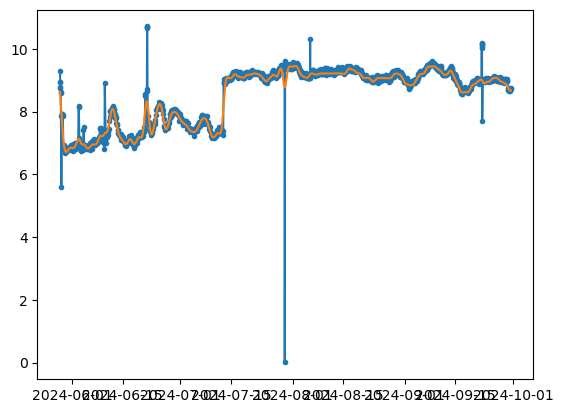

In [191]:
mean_var_per_cast = calc_mean_per_cast(ds, "TEMP")
mean_var_per_cast

mean_var_per_cast = mean_var_per_cast.swap_dims({"PROFILE_NUMBER": "TIME"})
regular = mean_var_per_cast.resample(TIME="1s").interpolate("linear")
regular_filled = regular.ffill("TIME").bfill("TIME")

fs = 1 # 1 samples per sec
cutoff = 1/(3600 * (24*2)) # remove changes faster than every 24 hours
geo_time_lag_filt = lowpass_filter(data = regular_filled, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

plt.scatter(mean_var_per_cast.TIME, mean_var_per_cast, marker = ".")
plt.plot(regular_filled.TIME, regular_filled)
plt.plot(regular_filled.TIME, geo_time_lag_filt); 

In [192]:
dt = np.diff(mean_var_per_cast["TIME"].values) / np.timedelta64(1, 'h')
print("Average time step (hours):", dt.mean(), dt.std())


Average time step (hours): 1.8178093933375397 0.7689510485031201


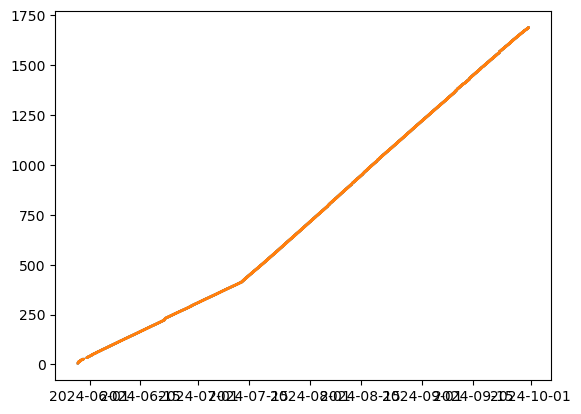

In [193]:
plt.plot(ds.TIME, ds.PROFILE_NUMBER)
plt.plot(ds.TIME.where(ds.PROFILE_NUMBER > 0), ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0))

## Dive rate

In [ ]:
def calculate_dive_rate(depth, time): 
    """
    Calculate the dive rate of the glider. 


    ARGS: 
        depth : Array-like
            Depth of glider in m. 
        time : Array-like
            Time variable

    RETURN:
        dive_rate : Array-like
            Dive rate i.e. vertical velocity of the glider in the water column. 
            
    """
    
    return dive_rate

## Geometric lag

In [194]:
def derive_geometric_time_lag(ds, dive_rate, pitch, d=None): 
    """
    Derive geometric time lag between DO optode and CTD based on dive rate and pitch, using mean dive rate and pitch per cast. 
    Following Woo & Gourcurr (2023) - IMOS. 
    
    ARGS: 
        dive_rate: array-like
            Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
        pitch: array-like
            Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. 
    RETURN: 
        geo_time_lag_filt : array-like
            Geometric time lag between OD optode and CTD (smoothed). Unit in s. 
            
    """

    # Find distance between CTD and DO optode (d)
    if isinstance(geo_time_lag, float): 
        print("Using following given distance between CTD and DO optode: ", d, " cm.")
    else: 
        d = 90 
        print("Using default distance between CTD and DO optode: ", d, " cm.")

    # Calculate the vertical velocity of travel (v)
    if (isinstance(dive_rate, float)) & (isinstance(pitch, float)): # TO DO : remove part between if and else later - not usable
        print("Using dive rate = ", dive_rate, "m s-1 and pitch = ", pitch, "deg in vertical velocity calculation. ")
    else: 
        # a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.
        mean_dive_rate_per_cast = calc_mean_per_cast(ds, var = "") # Calculate mean dive rate per cast - UNKNOWN VAR - TO DO 
        mean_pitch_per_cast = calc_mean_per_cast(ds, var = "GLIDER_PITCH") # Calculate mean pitch per cast 

        mean_vert_vel_per_cast = mean_dive_rate_per_cast / np.sin(mean_pitch_per_cast) # Calculate vertical velocity per cast
        mean_geo_time_lag = d / mean_vert_vel_per_cast # Calculate geometric time lag per cast

        # Interpolate geo time lag onto regular time grid 
        mean_geo_time_lag = mean_geo_time_lag.swap_dims({"PROFILE_NUMBER": "TIME"}) # set TIME as dimension
        mean_geo_time_lag_interp = mean_geo_time_lag.resample(TIME = "1s").interpolate("linear") # interpolate onto regular grid 
        mean_geo_time_lag_interp = mean_geo_time_lag_interp.ffill("TIME").bfill("TIME") # fill NaNs at edges (filter doesn't like NaNs)

        # b) Filter geometric time lag through low pass filter (separately for up and down casts). -- TO TEST 
        fs = 1 # 1 sample per s
        cutoff = 1/(3600*12) # remove changes faster than every 12 hours - TO DO: CHECK IF THIS NEEDS ADJUSTING
        geo_time_lag_filt_interp = lowpass_filter(data = mean_geo_time_lag_interp, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

        # Interpolate back onto original time frame/grid 
        geo_time_lag_filt = geo_time_lag_filt_interp.interp(TIME=geo_time_lag_filt.TIME)

    return geo_time_lag_filt

In [195]:
def apply_geometrical_alignment(ds, geo_time_lag, ctd_vars_to_align): 
    """
    Apply linear time shift using (filtered) geometric time lag. 
    ARGS: 
        ...

    RETURN:
        Geometrically aligned variables within ctd_vars_to_align 
    """
    # When geo_time_lag is constant 

    # a) Shift CTD data, incl. depth, in time to align with optode measurements.

    # b) Interpolate shifted CTD data incl. depth for optode measurement times.

    # c) Make sure to add shifted depth and interpolated CTD data to original CTD variables.

  


    # When geo_time_lag changes (array)
    
    # c) Shift CTD data incl. depth accordingly with calculated/shifted time lag for each cast 
    
    # d) Interpolate shifted CTD data incl. depth for optode measurement times.
    
    # e) Make sure to add shifted depth and interpolated CTD data to the original CTD variables.


    return 

In [196]:
def ctd_optode_geometrical_alignment(ds, geo_time_lag, dive_rate = None, pitch = None, d = None):
    """
    Geometrical alignment
    Adjust CTD data to optode location by correcting for geometric lag (seconds). 
    Default time_lag (3.9450) from IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual:
    https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf

    Using geo_time_lag: time shift in seconds to shift CTD measurements to alight with optode position. Default = 3.9450.
    
    ARGS:
        dive_rate: array-like
            Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
        pitch: array-like
            Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. 

    RETURN:
        shifted phase shift or CTD data? TO DO 
        
    """
    
    # Check if necessary variables are present in the dataset. -- TODO
    ctd_vars = ["TIME", "PRES", "PRAC_SALINITY", "TEMP", "DEPTH"]
    ctd_vars_to_align = []

    for ctd_var in ctd_vars: 
        if ctd_var not in ds.data_vars: 
            print(ctd_var, " not found in variable names. Geometric alignment with optode is not applied to this variable. ")
        else: 
            if bool(ds["ctd_var"].isnull().all()): 
                print(ctd_var, " contains only NaNs. Geometric alignment with optode is not applied to this variable. ")
            else:                 
                print("Geometric alignment will be applied to ", ctd_var)
                ctd_vars_to_align.append(ctd_var)

    # Find the geo_time_lag
    if geo_time_lag == 3.9450:
        print("Using default time lag to adjust CTD data for geometric lag: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    elif (geo_time_lag != 3.9450) & (isinstance(geo_time_lag, float)): 
        print("Using following time lag to adjust CTD data for geometric lag: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    elif geo_time_lag == "derive": 
        geo_time_lag = derive_geometric_time_lag(ds, dive_rate = None, pitch = None, d=None)
        print("Using following time lag derived from vertical velocity and pitch: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    else:
        geo_time_lag = 3.9450
        print("WARNING: input invalid for geometric lag correction. Using default of ", geo_time_lag, "s.")

    # Shift CTD variables and depth  with time_lag - IMOS applies it to BPAHSE... 
    # ctd_vars_to_align # only apply to the CTD vars that exist and contain data 
    apply_geometrical_alignment(ds, geo_time_lag, ctd_vars_to_align)
    


Checking on frequency of measurements: 

In [197]:
from scipy import stats

In [198]:
stats.describe(ds.TIME.diff(dim = "N_MEASUREMENTS")/np.timedelta64(1000000000, "ns"))
pd.Series((ds.TIME.diff(dim = "N_MEASUREMENTS")/np.timedelta64(1000000000, "ns")).values).describe()

DescribeResult(nobs=11331882, minmax=(np.float64(2.9952e-05), np.float64(2517915.851869184)), mean=np.float64(1.3735728397920015), variance=np.float64(774315.9139904008), skewness=np.float64(2420.687608277535), kurtosis=np.float64(6371277.306549641))

count    1.133188e+07
mean     1.373573e+00
std      8.799522e+02
min      2.995200e-05
25%      6.954962e-01
50%      1.003296e+00
75%      1.009644e+00
max      2.517916e+06
dtype: float64

<font color=orange> How can I shift data by 3.something seconds when time step is on average 10 seconds? </font> 

In [199]:
# optode_pipeline_settings.distance_CTD_optode

ctd_optode_geometrical_alignment(ds, geo_time_lag = optode_pipeline_settings.geo_time_lag, dive_rate = None, pitch = None, d = None)

TIME  not found in variable names. Geometric alignment with optode is not applied to this variable. 


KeyError: "No variable named 'ctd_var'. Variables on the dataset include ['TIME', 'OXYCOPVR', 'PLATFORM_TYPE', 'WATER_VELOC_FINAL_V_QC', 'CHLA_QC', ..., 'CHLA_ADJUSTED', 'CHLA_ADJUSTED_QC', 'UNCAL_PHASE_DOXY', 'CALPHASE_DOXY', 'TEMP_DOXY']"

<font color=orange> Linear time shift only works if a) measurement frequency of CTD is high enough i.e. milliseconds! and b) CTD and PHASE are measured a the same timepoint. 

There are lots of dphase measurements without temperature measurements. 

Will I need to interpolate the CTD data? 

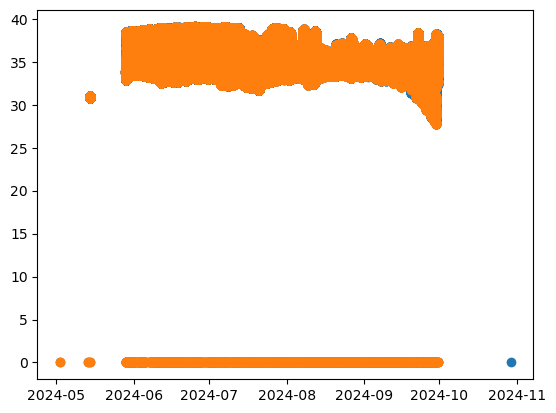

In [270]:
# This cell is outdated
plt.scatter(ds.TIME, ds.DPHASE_DOXY)
plt.scatter(ds.TIME.where(~ds.TEMP.isnull()), ds.DPHASE_DOXY.where(~ds.TEMP.isnull())); 

## Temporary "fake" geometrically-aligned variables

Just creating fake CTD variables that are used as placeholders for geometrically-aligned measurements. 

<font color=orange> All CTD data used for optode data processing from here onward use these placeholder data!! </font> 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Replace this temporary measure with actual geometrically shifted CTD data!! 
</div>

In [306]:
ds = ds.set_coords("TIME").swap_dims({"N_MEASUREMENTS": "TIME"}) # make time a coordinate and swap dimensions ie make dimension time
optode_meas_times = ds.TIME.where(~ds.BPHASE_DOXY.isnull(), drop = True) # find times when optode measurements were made 
temp_interp_onto_optode = ds.TEMP.interp(TIME = optode_meas_times) # interpolate TEMP onto these exact times
pracsal_interp_onto_optode = ds.PRAC_SALINITY.interp(TIME = optode_meas_times) # interpolate PRAC_SAL onto these exact times
pres_interp_onto_optode = ds.PRES.interp(TIME = optode_meas_times) # interpolate PRES onto these exact times
ds["TEMP_GEOSHIFT_OPTODE"] = temp_interp_onto_optode # copy interpolated CTD temperature measurements and pretend they're the optode's measurements 
ds["PRAC_SAL_GEOSHIFT_OPTODE"] = pracsal_interp_onto_optode # copy interpolated CTD salinity measurements and pretend they're the optode's measurements 
ds["PRES_GEOSHIFT_OPTODE"] = pres_interp_onto_optode # copy interpolated CTD pressure measurements and pretend they're the optode's measurements 

ds = ds.swap_dims({"TIME": "N_MEASUREMENTS"}) # swap back


***
# Hydrostatic pressure correction on UNCAL_PHASE_DOXY [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- UNCAL_PHASE_DOXY, i.e., uncalibrated phase, saved as `optode_pipeline_settings.uncal_phase_doxy`
- Pressure from the CTD, which has been adjusted for geometric lag
- Pressure correction coefficient, which depends on the optode type
</div>

Pressure can affect the optode's measured output in various ways. It affects the luminescence lifetime of the luminophores, quenching, and membrane O2 equilibrium level (Bittig et al., 2015a; Bittig et al., 2016). The effect on luminescence needs to be corrected on the <font color=pink> uncalibrated phase shift </font>, following Bittig et al. (2015a): 

$$UNCAL\_PHASE\_DOXY\_PCORR = UNCAL\_PHASE\_DOXY + Pcoef1 \frac{1}{1000} * PRES_{geoshift}$$

$UNCAL\_PHASE\_DOXY\_PCORR$ = Hydrostatic pressure corrected uncalibrated phase shift. 

$Pcoef1$ = Phase offset depending on the sensing foil and manufacturer, e.g., 0.1 deg per 1000 dbar for Aanderaa optodes. 

$PRES_{geoshift}$ = Pressure geometrically aligned to optode 

Note that the pressure used in this correction is the one that has been geometrically adjusted for the different locations of the optode and CTD on the glider. 

The pressure effect on quencing and on membrane O2 equilibrium level will be corrected on the oxygen concentration: MOLAR_DOXY, which is done after the salinity correction. 

<div class="alert alert-block alert-warning">
<b>Warning: </b> 
    
Pressure correction needs to be applied to the uncalibrated phase shift, _not_ the calibratd phase shift. If uncalibrated phase shift is not available, skip this hydrostatic pressure correction. 
</div>

In [296]:
def phase_hydrost_press_corr(optode_pipeline_settings, UNCAL_PHASE_DOXY, PRES_geoshift, Pcoef1=None): 
    """
    Correcting optode phase shift for hydrostatic pressure effect on luminescence lifetime. 
    Following best practice protocols, including Pcoef1 = 0.1 deg (Bittig et al., 2015). 

    
    ARGS:
        UNCAL_PHASE_DOXY: array-like
            Uncalibrated phase measurements. Unit = deg. 
            Thierry et al. (2025a): For 3830 optodes, PHASE = UNCAL_Phase = BPhase. For 4330 optodes, PHASE = TCPhase. 
        PRES_geoshift: array-like
            Pressure measurements that have previously been adjusted for geometric alignment with the optode. Unit = dbar. 
        Pcoef1 = float 
            Pressure correction coefficient. Unit = deg. Default = 0.1. 


    RETURN: 
        UNCAL_PHASE_Pcorr: array-like
            Uncalibrated phase shift values corrected for hydrostatic pressure effect. 
        
    Sources: 
        - Bittig et al. (2015): Bittig, H.C., B. Fielder, P. Fietzk and A. Kortzinger (2015): Pressure Response 
        of Aanderaa and Sea-Bird Oxygen Optodes. J. Atmos. Oceanic Tech., 32, 2305-2317, doi: 10.1175/JTECH-D-15-0108.1
        - Bittig et al. (2018): Bittig, H.C.,. A. Körtzinger, C. Neill, E. van Ooijen, J. N. Plant, J. Hahn, 
        K. S. Johnson, B. Yang, and S. R. Emerson (2018): Oxygen Optode Sensors: Principle, Characterization, 
        Calibration and Application in the Ocean. Front. Mar. Sci., 4, 429, doi: 10.3389/fmars.2017.00429
        - Thierry et al. (2025): Thierry V., H. Bittig, D. Gilbert, T. Kobayashi, K. Sato, C. Schmid, 2025: 
        Processing Argo OXYGEN data at the DAC level, v2.3.4, http://dx.doi.org/10.13155/39795
    """

    # Pressure correction coefficient (Pcoef1) differs per sensor
    if not Pcoef1: # If Pcoef1 argument = None, apply Pcoef1 from dictionary based on sensor type
        Pcoef1 = optode_pipeline_settings.Pcoef1_dict[optode_pipeline_settings.sensor_type]
        print("Hydrostatic pressure correction done with Pcoef1 = ", Pcoef1, "(", optode_pipeline_settings.sensor_type,")")
    else:
        print("Hydrostatic pressure correction done with GIVEN Pcoef1 = ", Pcoef1)

    # Apply hydrostatic pressure correction 
    UNCAL_PHASE_DOXY_PCORR = UNCAL_PHASE_DOXY + (Pcoef1*PRES_geoshift)/1000

    # Change first_pcorr_applied to 1
    optode_pipeline_settings.first_pcorr_applied = 1

    return UNCAL_PHASE_DOXY_PCORR

    

<div class="alert alert-block alert-success">
STEP: Apply hydrostatic pressure correction on uncalibrated phase shift (UNCAL_PHASE): 
</div>

In [307]:
optode_pipeline_settings.uncal_phase_doxy_pcorr # = optode_pipeline_settings.uncal_phase_doxy + "_PCORR" # set the name for the pressure corrected uncalibrated phase shift
ds[optode_pipeline_settings.uncal_phase_doxy_pcorr] =  phase_hydrost_press_corr(optode_pipeline_settings, UNCAL_PHASE_DOXY = ds[optode_pipeline_settings.uncal_phase_doxy], 
                                                                           PRES_geoshift = ds.PRES_GEOSHIFT_OPTODE, Pcoef1=None)


'UNCAL_PHASE_DOXY_PCORR'

Hydrostatic pressure correction done with Pcoef1 =  0.1 ( aa3830 )


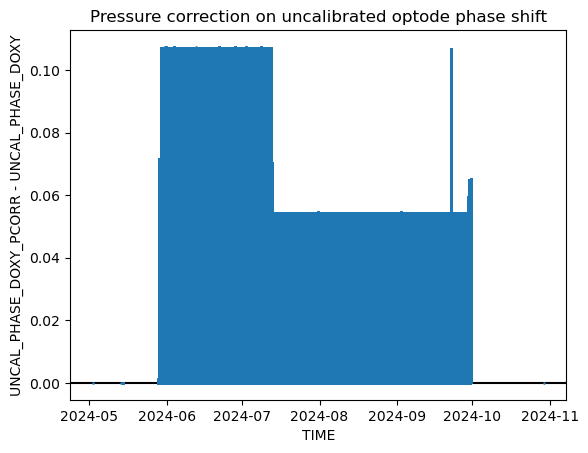

In [308]:
plt.scatter(ds.TIME, ds.UNCAL_PHASE_DOXY_PCORR - ds.UNCAL_PHASE_DOXY, marker = ".", s = 3)
plt.ylabel("UNCAL_PHASE_DOXY_PCORR - UNCAL_PHASE_DOXY")
plt.xlabel("TIME")
plt.axhline(y = 0, c = "k", zorder = 0)
plt.title("Pressure correction on uncalibrated optode phase shift");

In [309]:
pd.Series(ds.UNCAL_PHASE_DOXY_PCORR - ds.UNCAL_PHASE_DOXY).describe()

count    4.701946e+06
mean     3.628225e-02
std      2.589751e-02
min     -3.500000e-05
25%      1.583455e-02
50%      3.257498e-02
75%      4.957850e-02
max      1.073760e-01
dtype: float64

***
# Derive calibrated phase shift (CALPHASE_DOXY) [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>

- UNCAL_PHASE_DOXY_PCORR, i.e., uncalibrated phase corrected for pressure
- PhaseCoef calibration coefficients from the manufacturer
</div>

This is the temperature compensation step, converting the uncalibrated phase into a "calibrated phase". 

This step is the same for all Aanderaa optodes. 

- aa3830: BPhase (blue phase shift ) &rarr; Uncal_phase (uncalibrated phase shift) &rarr; Uncal_phase_pcorr &rarr; DPhase (calibrated phase shift)
- aa4330: C1RPhase and C2RPhase (blue and red phase shift) &rarr; TCPhase (uncalibrated phase shift) &rarr; TCPhase_Pcorr &rarr; CalPhase (calibrated phase shift)

We have aligned the naming of uncalibrated phase shifts among different optodes: UNCAL_PHASE_DOXY and UNCAL_PHASE_DOXY_PCORR. The calibrated phase shift will be named CALPHASE_DOXY. Note that this is the same as DPHASE_DOXY (Aanderaa 3830 series) and CALPHASE (Aanderaa 4330 series). 


In [300]:
def calculate_dphase_aa(ds, UNCAL_PHASE_DOXY_PCORR, cal_sheet_aa): 
    """
    Determine DPHASE (i.e., calibrated phase) using 3rd degree polynomial and UNCAL_PHASE_Pcorr. 

    ARGS:
        PhaseCoef0-3: floats (saved in cal_sheet_aa, i.e., the manufacturer calibration sheet)
            Phase shift coefficients provided by the manufacturer
        UNCAL_PHASE_Pcorr : array-like
            Uncalibrated phase shift of the optode, which has ideally been corrected for pressure. Unit = deg. 
    RETURN:
        DPHASE_DOXY data array added to dataset 
    
    """
    A = cal_sheet_aa.PhaseCoef0
    B = cal_sheet_aa.PhaseCoef1
    C = cal_sheet_aa.PhaseCoef2
    D = cal_sheet_aa.PhaseCoef3

    CALPHASE_DOXY = A + (B*UNCAL_PHASE_DOXY_PCORR) + (C*UNCAL_PHASE_DOXY_PCORR**2) + (D*UNCAL_PHASE_DOXY_PCORR**3)

    return CALPHASE_DOXY
    

<div class="alert alert-block alert-success">
STEP: Calculate calibrated phase (CALPHASE_DOXY) from uncalibrated phase (UNCAL_PHASE_DOXY), which has ideally been corrected for pressure (UNCAL_PHASE_DOXY_PCORR): 
</div>

In [310]:
print("Name for calibrated phase shift: ", optode_pipeline_settings.calphase_doxy)
# determine the calibrated phase shift
ds[optode_pipeline_settings.calphase_doxy] = calculate_dphase_aa(ds = ds, UNCAL_PHASE_DOXY_PCORR = ds[optode_pipeline_settings.uncal_phase_doxy_pcorr], cal_sheet_aa = cal_sheet_aa)

Name for calibrated phase shift:  CALPHASE_DOXY


***
# Phase shift to DO concentration (MOLAR_DOXY) [READY]

Convert CALPHASE_DOXY (i.e. calibrated phase) to MOLAR_DOXY (in umol L-1). 

<font color=orange> Note: we will call the variable MOLAR_DOXY_ADJUSTED instead of MOLAR_DOXY, to distinguish it from the MOLAR_DOXY calculated by the optode, which does not account for pressure and salinity corrections. </font> 

The way this is done is different for different optodes. Each optode also has several options. 


<div class="alert alert-block alert-warning">
<b>Careful! </b> 

For Aanderaa 4330, use the TEMP_DOXY data as input for temperature, because this temperature has been used for the determination of the calibration coefficients. Other steps need to use the CTD temperature (TEMP). 

For Aanderaa 3830, use the CTD temperature (TEMP), because this optode model has a slow response temperature sensor and using the temperature from the CTD has shown to lead to more accurate results. Subsequent processing steps also need to use the CTD temperature (TEMP). 
 
</div>




## Aanderaa 3930, 3835, 3975, 4130, and 4175 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- CALPHASE_DOXY, i.e., calibrated phase
- Temperature: CTD temperature, shifted by geometric lag! 
- Set of foil-dependant calibration coefficients from the manufacturer
</div>


<b> Aanderaa 3830, 3835, 3930, 3975, 4130, 4175 (and also 3930?!) </b>
- Method 1: Polynomial standard calibration (polynomial_standard)
- Method 2: Stern-Volmer equation (SVU)
- Method 3: modified Stern-Volmer equation for pO2 (SVU-modified).


<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Replace the interpolated CTD data input with properly geometric-lag-corrected CTD data. 
- [x] Aanderaa 3830 method 1
- [x] Aanderaa 3830 method 2
- [ ] Aanderaa 3830 method 3 (low priority - to be done in the future)
- [ ] Change MOLAR_DOXY name when calculated in this pipeline to MOLAR_DOXY_ADJUSTED to distinguish MOLAR_DOXY calculated by the optode!
</div>

### Polynomial method [READY]

In [320]:
def calphase_to_molar_doxy_aa38_poly(CALPHASE_DOXY, T, cal_sheet_aa): 
    """
    Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater). 
    This function applies to Aanderaa optodes 3930, 3835, 3975, 4130, and 4175 (and 3830) only. 
    Use CTD temperature as temperature input! 
    
    ARGS: 
        CALPHASE_DOXY : float or array-like
            Calibrated phase shift (degrees)
        T : float or array-like
            Temperature in degC. Use CTD Temperature! 
        FoilCalCoef : float
            20 foil-dependant calibration coefficient. Each set is associated to each batch of foils. Provide by manufacturer. 

    RETURN: 
        MOLAR_DOXY : dissolved oxygen concentration in umol L-1 for salinity = 0
    """

    print("Note: Make sure input temperature is CTD temperature (ideally adjusted for geometric lag)!")

    C0 = cal_sheet_aa.FoilCalCoef0 + cal_sheet_aa.FoilCalCoef1*T  + cal_sheet_aa.FoilCalCoef2*T**2 + cal_sheet_aa.FoilCalCoef3*T**3
    C1 = cal_sheet_aa.FoilCalCoef4 + cal_sheet_aa.FoilCalCoef5*T  + cal_sheet_aa.FoilCalCoef6*T**2 + cal_sheet_aa.FoilCalCoef7*T**3
    C2 = cal_sheet_aa.FoilCalCoef8 + cal_sheet_aa.FoilCalCoef9*T  + cal_sheet_aa.FoilCalCoef10*T**2 + cal_sheet_aa.FoilCalCoef11*T**3
    C3 = cal_sheet_aa.FoilCalCoef12 + cal_sheet_aa.FoilCalCoef13*T  + cal_sheet_aa.FoilCalCoef14*T**2 + cal_sheet_aa.FoilCalCoef15*T**3
    C4 = cal_sheet_aa.FoilCalCoef16 + cal_sheet_aa.FoilCalCoef17*T  + cal_sheet_aa.FoilCalCoef18*T**2 + cal_sheet_aa.FoilCalCoef19*T**3

    MOLAR_DOXY = C0 + C1*CALPHASE_DOXY + C2*CALPHASE_DOXY**2 + C3*CALPHASE_DOXY**3 + C4*CALPHASE_DOXY**4

    return MOLAR_DOXY

### SVU method [READY]

In [314]:
def calphase_to_molar_doxy_aa38_svu(CALPHASE_DOXY, T, cal_sheet_aa): 
    """
    Compute dissolved oxygen (MOLAR_DOXY) from the calibrated phase shift (CALPHASE_DOXY) using the modified Stern–Volmer equation. 
    This equation uses 2 temperature-dependent coefficients that are each defined by 3-order polynomials based on coefficients provided by the manufacturer, 
    and 2 temperature-independent coefficients from the manufacturer. 

    ARGS: 
        CALPHASE_DOXY : float or array-like
            Calibrated phase shift (degrees). 
        T : float or array-like
            Temperature in degC. Use CTD Temperature! 
            
    RETURN: 
        MOLAR_DOXY : dissolved oxygen concentration in umol L-1 for salinity = 0
    """

    # Polynomial evaluations for K0(T) and K1(T)
    
    K0 = (
        cal_sheet_aa.K0_coeffs0
        + cal_sheet_aa.K0_coeffs1 * T
        + cal_sheet_aa.K0_coeffs2 * T**2
        + cal_sheet_aa.K0_coeffs3 * T**3
    )

    K1 = (
        cal_sheet_aa.K1_coeffs0
        + cal_sheet_aa.K1_coeffs1 * T
        + cal_sheet_aa.K1_coeffs2 * T**2
        + cal_sheet_aa.K1_coeffs3 * T**3
    )

    # Apply Stern–Volmer equation
    MOLAR_DOXY = (cal_sheet_aa.F1 / (K0 * CALPHASE_DOXY + cal_sheet_aa.F2) - 1.0) * K1

    return MOLAR_DOXY

### SVU-modified method [NOT WRITTEN]

In [316]:
def calphase_to_molar_doxy_aa38_svu_mod(): 
    """
    
    ARGS: 

            
    RETURN: 
        MOLAR_DOXY : dissolved oxygen concentration in umol L-1 for salinity = 0
    """

    print("Code for this method has not been written yet. ")
    MOLAR_DOXY = 0
    
    return MOLAR_DOXY

### CALPHASE to MOLAR_DOXY [READY]

In [317]:
def calphase_to_molar_doxy_aa38(CALPHASE_DOXY, T, cal_sheet_aa, method = "poly"): 
    """

    ARGS: 
        CALPHASE_DOXY : float or array-like
            Calibrated phase shift (degrees)
        T : float or array-like
            Temperature in degC. Use CTD Temperature! 
        method: string
            Method for calculation. Choose from: "poly", "svu", or "svu-modified"
    
    """

    if method == "poly": 
        MOLAR_DOXY = calphase_to_molar_doxy_aa38_poly(CALPHASE_DOXY, T, cal_sheet_aa)
    elif method == "svu": 
        MOLAR_DOXY = calphase_to_molar_doxy_aa38_svu(CALPHASE_DOXY, T, cal_sheet_aa)
    elif method == "svu-modified":
        MOLAR_DOXY = calphase_to_molar_doxy_aa38_svu_mod(CALPHASE_DOXY, T, cal_sheet_aa)
    else: 
        print("ERROR: Does not recongise the method. Choose from 'poly', 'svu', or 'svu-modified'. ")


    return MOLAR_DOXY

<div class="alert alert-block alert-success">
STEP: Convert calibrated phase shift to oxygen concentration (MOLAR_DOXY): 
</div>

In [321]:
# For Aanderaa 3930, 3835, 3975, 4130, and 4175
ds["MOLAR_DOXY_ADJUSTED"] = calphase_to_molar_doxy_aa38(CALPHASE_DOXY = ds[optode_pipeline_settings.calphase_doxy], T = ds.TEMP_GEOSHIFT_OPTODE, cal_sheet_aa = cal_sheet_aa, method = "poly")


Note: Make sure input temperature is CTD temperature (ideally adjusted for geometric lag)!


## Aanderaa 4330, 4831, 4835 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>

- CALPHASE_DOXY, i.e., calibrated phase
- Temperature: optode temperature! (TEMP_DOXY)
- Set of foil-dependant calibration coefficients from the manufacturer
- Salinity (only required for certain methods)
</div>

For Aanderaa 4330, 4831, and 4835, the phase shift is converted into a molar concentration of oxygen (i.e., MOLAR_DOXY in umol L-1) in 3 ways, depending on whether the SVUFoilCoefs have been made available by the manufacturer. 

<b>Method 1 (and 2): Polynomial standard calibration </b>


<b>If the SVUFoilCoefs are unavailable </b>, MOLAR_DOXY is calculated from the oxygen solubility (cm3 / dm3; determined from Garcia & Gordon, 1992) and from percentage air saturation: 

$$C^\ast = exp [A_0 + A_1 * T_S + A_2 * T_S^2 + A_3 * T_S^3 + A_4 * T_S^4 + A_5 * T_S^5 + S * (B_0 + B_1 * T_S + B_2 * B_S^2 + B_3 * T_S^3) + C_0 * S^2]$$

, where 

$A_0$ - $A_5$ and $B_0$ - $B_3$ and $C_0$ are constants from Garvia & Gordon (1992), S is salinity, and $T_S$ is scaled temperature: 

$$T_S = ln(\frac{298.15 - t}{273.15 - t})$$

, where t is temperature in degC. <font color=orange> Note, use TEMP_DOXY </font> 

This method can be followed up by a linear 2-point adjustment, usually applied to Aanderaa optodes 4330 with serial number >= 1000. (Method 2)


<b>Method 3 (and 4): Stern-Volmer equation </b>

<b>If the SVUFoilCoefs are available</b>, apply the Stern/Volmer/Uchida formula: 

$$MOLAR\_DOXY = \frac{\frac{P_0}{P_c}-1}{K_{SV}}$$

, where 

$$K_{SV} = c_0 + c_1 * T + c_2 * T^2$$ 

$$P_0 = C_3 + C_4 * T $$

$$P_c = c_5 + c_6 * DPHASE\_DOXY\_Pcorr$$

, and T is temperature in degC. <font color=orange> Note, use TEMP_DOXY. </font> 

This method can be followed up by a linear 2-point adjustment, usually applied to Aanderaa optodes 4330 with serial number >= 1200. (Method 4)

<b>Method 5: modified Stern-Volmer equation </b>

This method follows Bittig et al. (2018), which calculates pO2 (partial pressure of O2) directly, which mean no salinity adjustment is necessary. 


<b> Aanderaa 4330, 4835, 4831 </b>
- Method 1: Polynomial standard calibration (polynomial_standard)
- Method 2: Standard calibration followed by 2-point adjustment (polynomial_standard-2point). Have merged this with method 1! 
- Method 3: Stern-Volmer equation (SVU)
- Method 4: Stern-Volmer equation followed by 2-point adjustment (SVU-2point). Haver merged this with method 3!
- Method 5: modified Stern-Volmer equation for pO2 (SVU-modified)

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Replace the interpolated CTD data input with properly geometric-lag-corrected CTD data. 
- [x] Aanderaa 4330 method 1
- [x] Aanderaa 4330 method 2 (merged with method 1)
- [x] Aanderaa 4330 method 3
- [x] Aanderaa 4330 method 4 (merged with method 3)
- [ ] Aanderaa 4330 method 5 (low priority)

</div>

### Oxygen solubility [READY]

In [322]:
def oxygen_solubility_garcia_gordon_1992(T, S = 35):
    """
    Calculate oxygen solubility C* (cm³/dm³) using Garcia & Gordon (1992).
    
    ARGS: 
        T : float or array
            Temperature in °C
        S : float
            Salinity (default = 35)

    RETURNS:
        C_star : float or array
            Oxygen solubility in cm³/dm³
    """

    # Garcia & Gordon (1992) coefficients
    A0 = 2.00856
    A1 = 3.22400
    A2 = 3.99063
    A3 = 4.80299
    A4 = 9.78188e-1
    A5 = 1.71069

    B0 = -6.24097e-3
    B1 = -6.93498e-3
    B2 = -6.90358e-3
    B3 = -4.29155e-3

    C0 = -3.11680e-7

    # Scaled temperature
    Ts = np.log((298.15 - T) / (273.15 - T))

    # Main Garcia & Gordon exponential term
    C_star = np.exp(
        A0
        + A1 * Ts
        + A2 * Ts**2
        + A3 * Ts**3
        + A4 * Ts**4
        + A5 * Ts**5
        + S * (B0 + B1 * Ts + B2 * Ts**2 + B3 * Ts**3)
        + C0 * S**2
    )

    return C_star

### Vapour pressure [READY]

In [323]:
def calculate_vapour_pressure(T):
    """
    Calculate water vapour pressure (hPa) from temperature (°C), following ... 

    ARGS: 
        T : float or array-like
            Temperature in degC (CHECK IF FROM OPTODE OR CTD)
    """
    return np.exp(52.57 - (6690.0 / (T + 273.15)) - 4.681 * np.log(T + 273.15))



### Oxygen partial pressure [READY]

In [324]:
def calculate_delta_p(CALPHASE_DOXY, T, C, m, n): 
    """
    Calculate partial pressure of oxygen (Δp) from CALPHASE_DOXY, temperature, and polynomial calibration coefficients, specific for the foil given by the manufacturer. 
    
    Δp = Σ C[i] * t^m[i] * dphase^n[i]

    ARGS:
        CALPHASE_DOXY : float or array
            Calibrated phase shift from the optode corrected for pressure
        T : float or array 
            Temperature (°C)
        C : list or array of coefficients C0 ... C27
        m : list or array of polynomial degrees for temperature
        n : list or array of polynomial degrees for dphase

    RETURNS
        Δp : float or array
            Partial pressure of oxygen in hPa. 
    """
    
    C = np.asarray(C)
    m = np.asarray(m)
    n = np.asarray(n)

    terms = C * (T ** m) * (CALPHASE_DOXY ** n)
    
    return np.sum(terms)

### Air saturation [READY]

In [325]:
def calculate_air_saturation(delta_p, p_vapour):
    """
    Calculate the air saturation (%), following ... 

    ARGS: 
        delta_p : float or array-like
            Partial pressure of oxygen in hPa
        p_vapour : float or array-like
            Water vapour pressure in hPa

    RETURNS:
        AirSaturation: float or array-like
            Air saturation percentage. 
    """

    NomAirPress = 1013.25 # nominal air pressure, hPa
    NomAirMix = 0.20946 # nominal oxygen content in air, hPa
    
    AirSaturation = (delta_p * 100) / ((NomAirPress - p_vapour) * NomAirMix)

    return AirSaturation

### Polynomial method [READY]

In [326]:
def calphase_to_molar_doxy_aa43_poly(CALPHASE_DOXY, T, S, cal_sheet_aa): 
    """
    Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater), using the standard polynomial calibration method. 
    This function applies to Aanderaa optodes 4330, 4831, and 4835 only. 
    Use temperature from the optode as temperature input: TEMP_DOXY. 

    ARGS : 
        CALPHASE_DOXY: float or array-like
            Calibrated phase shift in degrees. 
        T: float or array-like
            Temperature in degC. Use TEMP_DOXY (i.e. optode temperature). 
        S: float or array-like
            Practical salinity from CTD geometrically aligned with the optode. 
        Manufacturer calibration sheet: 
        method : string either, "SVU" or "poly"
            "SVU" signifies that the SVU method will be applied to calculate molar concentration of oxygen. 
            This is only possible of SVUFoilCoef0-6 are available in the manufacturer calibration sheet. 
            "poly" signifies that the molar oxygen concentration for oxygen will be calculated using oxygen solubility and air saturation. 
            The latter depends on the partial pressure of oxygen, which requires 27 polynomial coefficients from the manufacturer. 

    RETURN: 
        MOLAR_DOXY: Oxygen concentration in umol L-1 for salinity = 0. 
    
    """
    
    # Read in all foil coefficients
    c0 = cal_sheet_aa.FoilCoefA0
    c1 = cal_sheet_aa.FoilCoefA1
    c2 = cal_sheet_aa.FoilCoefA2
    c3 = cal_sheet_aa.FoilCoefA3
    c4 = cal_sheet_aa.FoilCoefA4
    c5 = cal_sheet_aa.FoilCoefA5
    c6 = cal_sheet_aa.FoilCoefA6
    c7 = cal_sheet_aa.FoilCoefA7
    c8 = cal_sheet_aa.FoilCoefA8
    c9 = cal_sheet_aa.FoilCoefA9
    c10 = cal_sheet_aa.FoilCoefA10
    c11 = cal_sheet_aa.FoilCoefA11
    c12 = cal_sheet_aa.FoilCoefA12
    c13 = cal_sheet_aa.FoilCoefA13
    c14 = cal_sheet_aa.FoilCoefB0
    c15 = cal_sheet_aa.FoilCoefB1
    c16 = cal_sheet_aa.FoilCoefB2
    c17 = cal_sheet_aa.FoilCoefB3
    c18 = cal_sheet_aa.FoilCoefB4
    c19 = cal_sheet_aa.FoilCoefB5
    c20 = cal_sheet_aa.FoilCoefB6
    c21 = cal_sheet_aa.FoilCoefB7
    c22 = cal_sheet_aa.FoilCoefB8
    c23 = cal_sheet_aa.FoilCoefB9
    c24 = cal_sheet_aa.FoilCoefB10
    c25 = cal_sheet_aa.FoilCoefB11
    c26 = cal_sheet_aa.FoilCoefB12
    c27 = cal_sheet_aa.FoilCoefB13

    # Read in all polynomial degrees for temperature
    m0 = cal_sheet_aa.FoilPolyDegT0
    m1 = cal_sheet_aa.FoilPolyDegT1
    m2 = cal_sheet_aa.FoilPolyDegT2
    m3 = cal_sheet_aa.FoilPolyDegT3
    m4 = cal_sheet_aa.FoilPolyDegT4
    m5 = cal_sheet_aa.FoilPolyDegT5
    m6 = cal_sheet_aa.FoilPolyDegT6
    m7 = cal_sheet_aa.FoilPolyDegT7
    m8 = cal_sheet_aa.FoilPolyDegT8
    m9 = cal_sheet_aa.FoilPolyDegT9
    m10 = cal_sheet_aa.FoilPolyDegT10
    m11 = cal_sheet_aa.FoilPolyDegT11
    m12 = cal_sheet_aa.FoilPolyDegT12
    m13 = cal_sheet_aa.FoilPolyDegT13
    m14 = cal_sheet_aa.FoilPolyDegT14
    m15 = cal_sheet_aa.FoilPolyDegT15
    m16 = cal_sheet_aa.FoilPolyDegT16
    m17 = cal_sheet_aa.FoilPolyDegT17
    m18 = cal_sheet_aa.FoilPolyDegT18
    m19 = cal_sheet_aa.FoilPolyDegT19
    m20 = cal_sheet_aa.FoilPolyDegT20
    m21 = cal_sheet_aa.FoilPolyDegT21
    m22 = cal_sheet_aa.FoilPolyDegT22
    m23 = cal_sheet_aa.FoilPolyDegT23
    m24 = cal_sheet_aa.FoilPolyDegT24
    m25 = cal_sheet_aa.FoilPolyDegT25
    m26 = cal_sheet_aa.FoilPolyDegT26
    m27 = cal_sheet_aa.FoilPolyDegT27

    # Read in all polynomial degrees for oxygen
    n0 = cal_sheet_aa.FoilPolyDegO0
    n1 = cal_sheet_aa.FoilPolyDegO1
    n2 = cal_sheet_aa.FoilPolyDegO2
    n3 = cal_sheet_aa.FoilPolyDegO3
    n4 = cal_sheet_aa.FoilPolyDegO4
    n5 = cal_sheet_aa.FoilPolyDegO5
    n6 = cal_sheet_aa.FoilPolyDegO6
    n7 = cal_sheet_aa.FoilPolyDegO7
    n8 = cal_sheet_aa.FoilPolyDegO8
    n9 = cal_sheet_aa.FoilPolyDegO9
    n10 = cal_sheet_aa.FoilPolyDegO10
    n11 = cal_sheet_aa.FoilPolyDegO11
    n12 = cal_sheet_aa.FoilPolyDegO12
    n13 = cal_sheet_aa.FoilPolyDegO13
    n14 = cal_sheet_aa.FoilPolyDegO14
    n15 = cal_sheet_aa.FoilPolyDegO15
    n16 = cal_sheet_aa.FoilPolyDegO16
    n17 = cal_sheet_aa.FoilPolyDegO17
    n18 = cal_sheet_aa.FoilPolyDegO18
    n19 = cal_sheet_aa.FoilPolyDegO19
    n20 = cal_sheet_aa.FoilPolyDegO20
    n21 = cal_sheet_aa.FoilPolyDegO21
    n22 = cal_sheet_aa.FoilPolyDegO22
    n23 = cal_sheet_aa.FoilPolyDegO23
    n24 = cal_sheet_aa.FoilPolyDegO24
    n25 = cal_sheet_aa.FoilPolyDegO25
    n26 = cal_sheet_aa.FoilPolyDegO26
    n27 = cal_sheet_aa.FoilPolyDegO27

    # Put all coefficients and polynomial degrees into lists
    C = [c0, c1, c2, c3, c4, c5, c6, c7, c8, c9, c10, c11, c13, c14, 
        c15, c16, c17, c18, c19, c20, c21, c22, c23, c24, c25, c26, c27]
    m = [m0, m1, m2, m3, m4, m5, m6, m7, m8, m9, m10, m11, m13, m14, 
        m15, m16, m17, m18, m19, m20, m21, m22, m23, m24, m25, m26, m27]
    n = [n0, cn, n2, n3, n4, n5, n6, n7, n8, n9, n10, n11, n13, n14, 
        n15, n16, n17, n18, n19, n20, n21, n22, n23, n24, n25, n26, n27]
    
    C_star = oxygen_solubility_garcia_gordon_1992(T = T, S = S) # oxygen solubility (cm3/dm3), calculated from Garcia & Gordon (1992)
    
    delta_p = calculate_delta_p(CALPHASE_DOXY = CALPHASE_DOXY, T = T, C = C, m = m, n = n) # calculate the partial pressure of oxygen (hPa)
    p_vapour = calculate_vapour_pressure(T) # calculate water vapour pressure (hPa)
    AirSaturation = calculate_air_saturation(delta_p, p_vapour) # calculate air saturation (%)
    
    MOLAR_DOXY_ = (C_star * 44.659 * AirSaturation) / 100 # calculate molar oxygen concentration for salinity = 0, not yet corrected with final calibration

    # Optional two-point adjustment. Set ConcCoef1 = 1 and ConcCoef0 = 0 if this adjustment shouldn't be applied. 
    MOLAR_DOXY = MOLAR_DOXY_ * cal_sheet_aa.ConcCoef1 + cal_sheet_aa.ConcCoef0 # Calculate corrected molar oxygen concentration for salinity = 0

    return MOLAR_DOXY
    

### SVU method [READY]

In [336]:
def calphase_to_molar_doxy_aa43_svu(CALPHASE_DOXY, T, cal_sheet_aa): 
    """
    Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater), using the SVU method. 
    This method is only possible of SVUFoilCoef0-6 are available in the manufacturer calibration sheet. 
    This function applies to Aanderaa optodes 4330, 4831, and 4835 only. 
    Use temperature from the optode for temperature input: TEMP_DOXY

    ARGS : 
        CALPHASE_DOXY: float or array-like
            Calibrated phase shift in degrees. 
        T: float or array-like
            Temperature in degC. Use TEMP_DOXY (i.e. optode temperature). 
        S: float or array-like
            Practical salinity from CTD geometrically aligned with the optode. 
        Manufacturer calibration sheet: 

    RETURN: 
        MOLAR_DOXY: Oxygen concentration in umol L-1 for salinity = 0. 
    
    """
    
    # Find teh SVU Foil Coefficients 
    c0 = cal_sheet_aa.SVUFoilCoef0
    c1 = cal_sheet_aa.SVUFoilCoef1
    c2 = cal_sheet_aa.SVUFoilCoef2
    c3 = cal_sheet_aa.SVUFoilCoef3
    c4 = cal_sheet_aa.SVUFoilCoef4
    c5 = cal_sheet_aa.SVUFoilCoef5
    c6 = cal_sheet_aa.SVUFoilCoef6
    
    K_SV = c0 + c1*T + c2*T**2
    P0 = c3 + c4*T
    Pc = c5 + c6*CALPHASE_DOXY # Use pressure corrected DPHASE

    # Apply Stern-Volmer equation
    MOLAR_DOXY_ = ((P0 / Pc) - 1) / K_SV

    # Optional two-point adjustment. Set ConcCoef1 = 1 and ConcCoef0 = 0 if this adjustment shouldn't be applied. 
    MOLAR_DOXY = MOLAR_DOXY_ * cal_sheet_aa.ConcCoef1 + cal_sheet_aa.ConcCoef0 # Calculate corrected molar oxygen concentration for salinity = 0

    return MOLAR_DOXY

### SVU-modified method 

In [330]:
def calphase_to_molar_doxy_aa43_svu_mod(): 
    """
    
    ARGS: 

            
    RETURN: 
        MOLAR_DOXY : dissolved oxygen concentration in umol L-1 for salinity = 0
    """

    print("Code for this method has not been written yet. ")
    MOLAR_DOXY = 0
    
    return MOLAR_DOXY

### CALPHASE to MOLAR_DOXY

In [333]:
def calphase_to_molar_doxy_aa43(CALPHASE_DOXY, T, cal_sheet_aa, S = None, method = "svu"): 
    """
     Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater), using the SVU method. 
    This method is only possible of SVUFoilCoef0-6 are available in the manufacturer calibration sheet. 
    This function applies to Aanderaa optodes 4330, 4831, and 4835 only. 
    Use temperature from the optode for temperature input: TEMP_DOXY

    ARGS : 
        CALPHASE_DOXY: float or array-like
            Calibrated phase shift in degrees. 
        T: float or array-like
            Temperature in degC. Use TEMP_DOXY (i.e. optode temperature). 
        S: float or array-like
            Practical salinity from CTD geometrically aligned with the optode. S needs to be given if method = poly or poly-2point. 
        method : string
            Method must be 'poly', 'svu', 'svu-modified'
        cal_sheet_aa : Manufacturer calibration sheet: 

    RETURN: 
        MOLAR_DOXY: Oxygen concentration in umol L-1 for salinity = 0. 


    ARGS: 
        CALPHASE_DOXY : float or array-like
            Calibrated phase shift (degrees)
        T : float or array-like
            Temperature in degC. Use CTD Temperature! 
        method: string
            Method for calculation. Choose from: "poly", "poly-2point", "svu", "svu-2point", or "svu-modified"
    
    """

    if method == "poly": 
        MOLAR_DOXY = calphase_to_molar_doxy_aa43_poly(CALPHASE_DOXY, T, S, cal_sheet_aa)
    elif method == "svu": # choose this one if svu coefficients are available
        MOLAR_DOXY = calphase_to_molar_doxy_aa43_svu(CALPHASE_DOXY, T, cal_sheet_aa)
    elif method == "svu-modified":
        MOLAR_DOXY = calphase_to_molar_doxy_aa43_svu_mod(CALPHASE_DOXY, T, cal_sheet_aa)
    else: 
        print("ERROR: Does not recongise the method. Choose from 'poly', 'poly-2point', 'svu', 'svu-2point', or 'svu-modified'. ")


    return MOLAR_DOXY

<div class="alert alert-block alert-success">
STEP: Convert calibrated phase shift (CALPHASE) to oxygen concentration (MOLAR_DOXY): 
</div>

In [338]:
# For Aanderaa 4330, 4831, 4835

ds["MOLAR_DOXY_ADJUSTED"] = calphase_to_molar_doxy_aa43(CALPHASE_DOXY = ds[optode_pipeline_settings.calphase_doxy], T = ds["TEMP_DOXY"], S = ds["PRAC_SAL_GEOSHIFT_OPTODE"], cal_sheet_aa = cal_sheet_aa)



***
# Salinity correction [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>
    
- Salinity (geometric-lag adjusted)
- Temperature (geomatric-lag adjusted)
- MOLAR_DOXY(_ADJUSTED)
</div>

The MOLAR_DOXY value determined by the optode assumes salinity = zero. The salinity correction is applied as follows: 

$$
c_{\mathrm{O_2,adj}}^{S} =
\frac{1013.25 - p_{\mathrm{H_2O}}(\vartheta, 0)}
     {1013.25 - p_{\mathrm{H_2O}}(\vartheta, S)}
\; S_{\mathrm{Corr}} \;
c_{\mathrm{O_2,adj}}^{0}
$$


where:

- $c_{\mathrm{O_2,adj}}^{S}$ is MOLAR_DOXY_PSAL

- $c_{\mathrm{O_2,adj}}^{0}$ is MOLAR_DOXY_ADJUSTED

- $p_{\mathrm{H_2O}}(\vartheta, S)$ is the **water vapor pressure**, which depends on temperature and salinity (Weiss & Price, 1980).

- $S_{\mathrm{Corr}}$ is the **salinity-dependent $O_{2}$ solubility correction factor**, calculated following Garcia & Gordon (1992) using the Benson & Krause refit.


The correction factor $S_{\mathrm{Corr}}$ is computed from scaled temperature $T_s$ as:

$$
S_{\mathrm{Corr}} =
\exp\left[
(S - S_{\mathrm{preset}})\left(
B_0 + B_1 T_s + B_2 T_s^2 + B_3 T_s^3
\right)
+ C_0 \left(S^2 - S_{\mathrm{preset}}^2\right)
\right]
$$

with:

- Scaled temperature:  
  $$
  T_s = \ln\left(\frac{298.15 - T}{273.15 + T}\right)
  $$

- Salinity used by the optode calibration: $S_{\mathrm{preset}}$  
  (often **35** for glider processing, but we will use the geometrically shifted salinity measured by the CTD on the glider)

## Partial pressure of water vapour [READY]

In [339]:
def ph2o_weiss_price_1980(S, T): 
    """ 
    Calculate the partial pressure of water vapour, following Weiss & Price (1980). 
    Range 273 to 313K and 0--40% salinity
    Standard error of 0.015% of pH2O, an average of about 5 × 10 -6 atm 
    over this range (Weiss&Price, 1980)

    ARGS: 
        S : float or array-like 
            Salinity (practical)
        T : float or array-like
            Temperature (degC). 

    RETURNS: 
        ph2o : float or array-like
            Partial pressure of water vapour (mbar). 

    CITATION: 
        Weiss, R. F., & Price, B. A. (1980). Nitrous oxide solubility in water 
    and seawater. Marine chemistry, 8(4), 347-359.
    """

    T = T+273.15 # Convert degrees C to Kelvin
    
    # Constants from polynomial equation 10 in Weiss&Price, 1980.
    A = 24.4543
    B = -67.4509
    C = -4.8489
    D = -0.000544
    
    # Equation 10 in Weiss&Price, 1980
    ph2o = 1013.25 * np.exp(A + B*(100/T) + C*np.log(T/100) + D*S)
    
    return ph2o


## SCorr [READY]

In [340]:
def apply_oxygen_solubility_salinity_correction(S, T, Spreset=0):
    """
    Compute the salinity correction factor SCorr from Garcia & Gordon (1992), using the Benson & Krause refit.
    Also see Bittig et al. (2016). 

    ARGS: 
        S : float or array
            Actual salinity.
        T : float or array
            Temperature in °C.
        Spreset : float, optional
            Reference salinity (e.g., 0 for freshwater or 35 for preset seawater).

    RETURNS: 
        SCorr : float or array
            SCorr salinity correction factor.
    """

    # Coefficients (Garcia & Gordon 1992 – Benson & Krause refit)
    B0 = -6.24523e-3
    B1 = -7.37614e-3
    B2 = -1.03410e-2
    B3 = -8.17083e-3
    C0 = -4.88682e-7

    # Scaled temperature term Ts
    Ts = np.log((298.15 - T) / (273.15 + T))

    # SCorr computation
    SCorr = np.exp(
        (S - Spreset) * (B0 + B1*Ts + B2*(Ts**2) + B3*(Ts**3))
        + C0 * ((S**2) - (Spreset**2))
    )

    return SCorr

In [342]:
def apply_salinity_correction(MOLAR_DOXY, T, S, Spreset = 0): 
    """
    Apply salinity correction to molar oxygen concentrations according to Bittig et al. (2016). 

    ARGS: 
        MOLAR_DOXY: float or array-like
            Molar oxygen concentration calculated for salinity = 0 (umol L-1)
        T : float or array-like
            Temperature (degC)
        S : float or array-like
            Actual salinity 
        Spreset : float, optional
            Reference salinity (e.g., 0 for freshwater or 35 for preset seawater).

    RETURNS: 
        MOLAR_DOXY_PSAL : float or array-like
            Molar oxygen concentration corrected for actual salinity (umol L-1)
    
    """

    # Calculate factor with partial pressure of water vapour, following Weiss & PRice (1980)
    A = 1013.25 - ph2o_weiss_price_1980(S = Spreset, T = T) # 1 mbar = 1hPa 
    B = 1013.25 - ph2o_weiss_price_1980(S = S, T = T) # 1 mbar = 1hPa 

    S_Corr = apply_oxygen_solubility_salinity_correction(S = S, T = T, Spreset=0)

    MOLAR_DOXY_PSAL = (A/B) * S_Corr * MOLAR_DOXY

    return MOLAR_DOXY_PSAL

    

<div class="alert alert-block alert-success">
STEP: Apply salinity correction: 
</div>

In [343]:
T = ds.TEMP_GEOSHIFT_OPTODE
S = ds.PRAC_SAL_GEOSHIFT_OPTODE
MOLAR_DOXY = ds["MOLAR_DOXY_ADJUSTED"]
ds["MOLAR_DOXY_PSAL"] = apply_salinity_correction(MOLAR_DOXY, T, S, Spreset = 0)


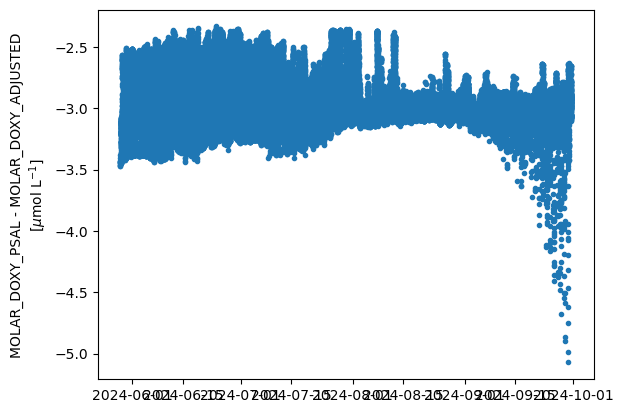

In [353]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL - ds.MOLAR_DOXY_ADJUSTED, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL - MOLAR_DOXY_ADJUSTED\n[$\mu$mol L$^{-1}$]");

***
# CALPHASE_DOXY to pO2 [NOT WRITTEN]

Bittig et al. (2016) suggest that the salinity correction can be skipped when accounting for the O2-T response using a different mathematical model that determines the oxygen output in terms of partial pressure (pO2) instead of molar concentration (MOLAR_DOXY) (Uchida et al., 2010). pO2 is independent of salinity, and thus a salinity correction is not applicable. pO2 can then be converted to MOLAR_DOXY, using the SCOR WG 132 recommendations for convertions. 

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will implement the possibility of this step at a later stage. 
</div>

***
# Hydrostatic pressure correction [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>

- MOLAR_DOXY_PSAL, i.e., salinity-corrected oxygen concentration (umol L-1)
- Pressure from CTD that has been corrected for geometric lag (dbar)
</div>

Correct for hydrostatic pressure correction on quenching and membrane O2 equilibrium. The pressure effect on oxygen quenching is corrected by applying a multiplicative factor to the salinity-corrected oxygen concentration:

$$
\mathrm{MOLAR\_DOXY\_{PSAL\_PCORR}} =
\mathrm{MOLAR\_DOXY\_{PSAL}} \times
\left[
1 +
\left( P_{\mathrm{coef2}} \, T + P_{\mathrm{coef3}} \right)
\frac{\mathrm{P}}{1000}
\right]
$$

where:

- $T$ is the CTD temperature (°C), ideally adjusted for geometric lag 
- $\mathrm{P}$ is the pressure (dbar), ideally adjusted for geometric lag 
- $P_{\mathrm{coef2}}$ and $P_{\mathrm{coef3}}$ are empirical pressure-response coefficients  

The correct set of coefficients depends on whether **BPhase / TCPhase**, i.e., uncalibrated phase shift, has already been corrected for the pressure effect.

1. If uncalibrated phase shift *has been corrected* for pressure ($P_{\mathrm{coef1}} = 0.1$):

$$
P_{\mathrm{coef2}} = 2.2 \times 10^{-4}, \qquad
P_{\mathrm{coef3}} = 4.19 \times 10^{-2}
$$

2. If BPhase / TCPhase *has NOT been corrected* for pressure ($P_{\mathrm{coef1}} = 0$):

$$
P_{\mathrm{coef2}} = 2.5 \times 10^{-4}, \qquad
P_{\mathrm{coef3}} = 3.28 \times 10^{-2}
$$

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [x] Incorporate Argo: Thierry et al., 2025a p 28-29.
- [x] Check units of Pcoefs and pressure
</div>



In [369]:
def DO_hydrost_press_corr_aa(MOLAR_DOXY_PSAL, P, T, optode_pipeline_settings):
    """
    Correct for hydrostatic pressure effect on quenching and membrane O2 equilibrium for Aanderaa optodes (also SeaBird optodes). 

    ARGS:
        MOLAR_DOXY_PSAL: array-like
            Salinity-corrected oxygen concentration. Unit = umol L-1. 
        P: array-like
            Pressure adjusted for geometric lag. Unit = dbar. 
        T: array-like
            Temperature from the CTD adjusted for geometric lag. Unit = degrees Celsius. 

    RETURNS: 
        MOLAR_DOXY_PSAL_PRES : array-like
            Pressure corrected oxygen concentration (umol L-1). 

    Sources:
        - Bittig et al. (2015): Bittig, H.C., B. Fielder, P. Fietzk and A. Kortzinger (2015): 
        Pressure Response of Aanderaa and Sea-Bird Oxygen Optodes. J. Atmos. Oceanic Tech., 
        32, 2305-2317, doi: 10.1175/JTECH-D-15-0108.1
        - Thierry et al. (2025a)
        
    """

    # Where did this equation come from? 
    # MOLAR_DOXY_PSAL_PRES = MOLAR_DOXY_PSAL *(1.0 + ((0.032 * P) / 1000))

    if optode_pipeline_settings.first_pcorr_applied == 1: 
        # If uncalibrated phase shift has been corrected for pressure effect # Bittig et al., 2018; Thierry et al., 2025a
        Pcoef2 = 0.00022 # 0.022 when working in bar
        Pcoef3 = 0.0419 # 4.19 when working in bar
    elif optode_pipeline_settings.first_pcorr_applied == 0: 
        # If uncalibrated phase shift has not been corrected for pressure effect # Thierry et al., 2025a
        Pcoef2 = 0.00025 # 0.025 when working in bar
        Pcoef3 = 0.0328 # 3.28 when working in bar
    else: 
        print("first_pcorr_applied in settings needs to be set to 0 (pressure correction on phase shift not applied) or 1 (pressure correction on phase shift applied).")
    
    MOLAR_DOXY_PSAL_PRES = MOLAR_DOXY_PSAL *(1.0 + ((Pcoef2 * T + Pcoef3) * P) / 1000)

    return MOLAR_DOXY_PSAL_PRES


    

<div class="alert alert-block alert-success">
STEP: Apply second pressure correction: 
</div>

In [370]:
MOLAR_DOXY_PSAL = ds.MOLAR_DOXY_PSAL
P = ds.PRES_GEOSHIFT_OPTODE
T = ds.TEMP_GEOSHIFT_OPTODE
ds["MOLAR_DOXY_PSAL_PRES"] = DO_hydrost_press_corr_aa(MOLAR_DOXY_PSAL, P, T, optode_pipeline_settings)

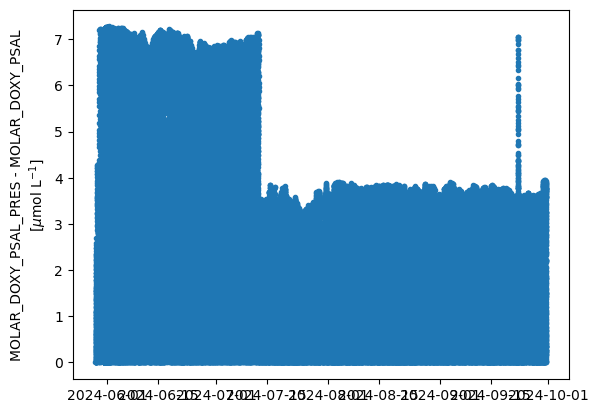

In [371]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL_PRES - ds.MOLAR_DOXY_PSAL, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL_PRES - MOLAR_DOXY_PSAL\n[$\mu$mol L$^{-1}$]");

Combined effect of pressure and salinity adjustment on MOLAR_DOXY_ADJUSTED: 

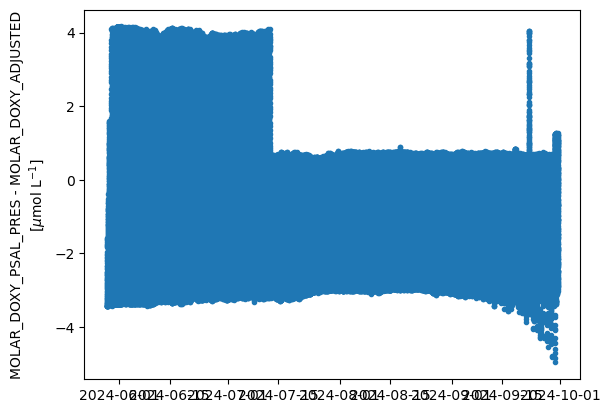

In [367]:
plt.scatter(ds.TIME, ds.MOLAR_DOXY_PSAL_PRES - ds.MOLAR_DOXY_ADJUSTED, marker = ".");
plt.ylabel("MOLAR_DOXY_PSAL_PRES - MOLAR_DOXY_ADJUSTED\n[$\mu$mol L$^{-1}$]");

---
# Conservative temperature [NOT WRITTEN]

<font color=orange> Am still investigating whether conservative temperature is necessary to calculate oxygen saturation (and density). Consider this later. </font>

***
# MOLAR_DOXY to DOXY [IN PROGRESS]

Convert MOLAR_DOXY (umol L-1) to DOXY (umol kg-1), following SCOR WG 142 recommendations. 


<div class="alert alert-block alert-warning">
<b>To do: </b> 

- [ ] Potential density calculation: I cannot find method based on Fofonoff and Millard (1983). Using teos10 at the moment. 
</div>
 

In [373]:
def calculate_potential_density_teos10(S, T, P, lon, lat): 
    """
    Calculate potential density of seawater (kg L-1) referenced to a hydrostatic pressure of 0 dbar and using practical salinity.
    Using the Gibbs Seawater Python implementation of the Thermodynamic Equation of Seawater 2010 (TEOS-10). 

    ARGS: 
        T : array-like, float
            Temperature in degrees Celsius
        S : array-like, float
            Practical salinity 
        P : array-like, float
            Pressure in dbar. 
        lon : array-like, float
            Longitude -360 to 360 degrees
        lat : array-like, float
            Latitude -90 to 90 degrees

    RETURN: 
        rho : potential density of seawater in kg L-1. 
    """

    # Calculate absolute salinity
    SA = gsw.conversions.SA_from_SP(S, P, lon, lat)

    # Calculate conservative temperature
    CT = gsw.conversions.CT_from_t(SA, T, P)

    # Calculate potential density = potential density anomaly + 1000 kg m-3
    rho = gsw.density.sigma0(SA, CT) + 1000 # kg m-3


    return rho

In [ ]:
def calculate_potential_density_unesco(S, T): 
    """
    Calculate potential density of seawater (kg L-1) referenced to a hydrostatic pressure of 0 dbar and using practical salinity.
    Bittig et al. (2016) recommends using equation of state based on Fofonoff and Millard (1983) and Millero et al. (1980). 
    Potential density at 0 dbar and potential temperature. 

    ARGS: 
        T : array-like, float
            Temperature in degrees Celsius
        S : array-like, float
            Practical salinity 

    RETURN: 
        rho : potential density of seawater in kg L-1. 
    """


    

    return rho

In [377]:
def o2_umolL_to_umolkg(MOLAR_DOXY, T, S, lon = None, lat = None):
    """
    Convert oxygen from µmol/L to µmol/kg using potential density of seawater (kg L-1) referenced to a hydrostatic pressure of 0 dbar and using practical salinity.

    For potential debsity, Bittig et al. (2016) recommends using equation of state based on Fofonoff and Millard (1983) and Millero et al. (1980). 
    
    
    ARGS: 
        MOLAR_DOXY : array or float
            Oxygen concentration in µmol/L
        T : array or float
            Temperature (°C)
        S : array or float
            Practical salinity (psu)
        lon : array-like, float
            Longitude -360 to 360 degrees. Required if potential density is calculated according to TEOS10. 
        lat : array-like, float
            Latitude -90 to 90 degrees. Required if potential density is calculated according to TEOS10. 
    
    RETURNS: 
        DOXY : array or float
            Oxygen concentration in µmol/kg
    """
    # rho_kgm3 = calculate_potential_density_unesco(S, T)     # kg/m^3 # NOT YET IMPLEMENTED 
    rho_kgm3 = calculate_potential_density_teos10(S = S, T = T, P = P, lon = lon, lat = lat) # kg/m^3  # USING THIS ONE FOR NOW
    rho_kgl = rho_kgm3 / 1000.0         # convert to kg/L

    DOXY = MOLAR_DOXY / rho_kgl

    return DOXY

<div class="alert alert-block alert-success">
STEP: Convert MOLAR_DOXY to DOXY: 
</div>

In [378]:
ds["DOXY"] = o2_umolL_to_umolkg(MOLAR_DOXY = ds.MOLAR_DOXY_ADJUSTED, T = ds.TEMP_GEOSHIFT_OPTODE, S = ds.PRAC_SAL_GEOSHIFT_OPTODE, lon = ds.LONGITUDE, lat = ds.LATITUDE)


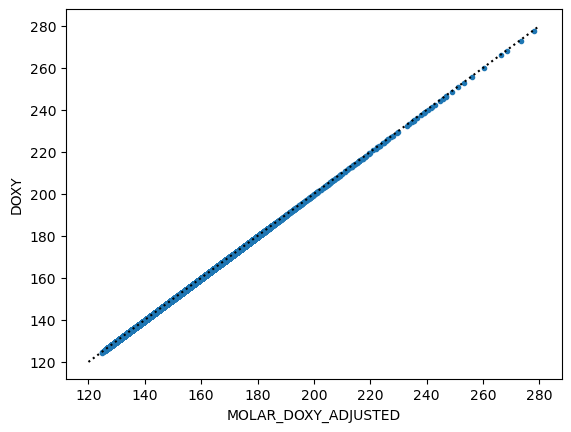

In [382]:
plt.scatter(ds.MOLAR_DOXY_ADJUSTED, ds.DOXY, marker = ".")
plt.plot([120, 280], [120, 280], c = "k", ls = ":")
plt.xlabel("MOLAR_DOXY_ADJUSTED")
plt.ylabel("DOXY"); 

***
# Tests [IN PROGRESS]

<font color=pink> These tests need to be done on oxygen in umol kg-1. </font> 

## Global range check [READY]

Global range check for DOXY and TEMP_DOXY: 

- -5 < DOXY < 600
- -2.5 < TEMP_DOXY < 40


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yml. 
</div>


In [383]:
def global_range_check(DOXY, TEMP_DOXY):
    """
    Apply global range checks for DOXY and TEMP_DOXY.
    
    ARGS: 
        DOXY : float or array-like
            Oxygen concentration (µmol kg-1).
        TEMP_DOXY : float or array-like
            Optode temperature (°C).

    RETURNS: 
        qc_doxy : ndarray
            QC flags for DOXY (1 = good, 4 = bad).
        qc_temp : ndarray
            QC flags for TEMP_DOXY (1 = good, 4 = bad).
    """

    doxy = np.asarray(doxy, dtype=float)
    temp_doxy = np.asarray(temp_doxy, dtype=float)

    # Initialize QC flags with "1" (good)
    qc_doxy = np.ones_like(doxy, dtype=int)
    qc_temp = np.ones_like(temp_doxy, dtype=int)

    # Apply global range checks
    qc_doxy[(doxy < -5) | (doxy > 600)] = 4
    qc_temp[(temp_doxy < -2.5) | (temp_doxy > 40)] = 4

    return qc_doxy, qc_temp

## Regional range check [READY]

Flag temperatures outside **region-specific valid ranges** as 4 (bad):  
- Red Sea: 21.7 – 40.0 °C  
- Mediterranean Sea: 10.0 – 40.0 °C  

<div class="alert alert-block alert-warning">
<b> To do: </b>

- [ ] Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

In [385]:
from matplotlib.path import Path


In [384]:
def regional_range_check(LAT, LON, TEMP_DOXY):
    """
    Apply regional range checks for TEMP_DOXY in the Red Sea and Mediterranean Sea.

    ARGS:
        LAT : float or array-like
            Latitude of observations (°N).
        LON : float or array-like
            Longitude of observations (°E).
        TEMP_DOXY : float or array-like
            Optode temperature (°C).

    RETURNS:
        qc_temp : ndarray
            QC flags for TEMP_DOXY (1 = good, 4 = bad).
    """

    lat = np.asarray(LAT, dtype=float)
    lon = np.asarray(LON, dtype=float)
    temp_doxy = np.asarray(TEMP_DOXY, dtype=float)

    # Initialize QC flags with "1" (good)
    qc_temp = np.ones_like(temp_doxy, dtype=int)

    # Define polygons for Red Sea and Mediterranean Sea
    red_sea_poly = Path([
        (10, 40),
        (20, 50),
        (30, 30),
        (10, 40)
    ])
    
    med_sea_poly = Path([
        (30, -6),
        (30, 40),
        (40, 35),
        (42, 20),
        (50, 15),
        (40, -5),
        (30, -6)
    ])
    
    # Check which points are inside each polygon
    points = np.column_stack((lat, lon))
    in_red_sea = red_sea_poly.contains_points(points)
    in_med_sea = med_sea_poly.contains_points(points)

    # Apply regional temperature ranges
    qc_temp[in_red_sea & ((temp_doxy < 21.7) | (temp_doxy > 40.0))] = 4
    qc_temp[in_med_sea & ((temp_doxy < 10.0) | (temp_doxy > 40.0))] = 4

    return qc_temp


---
## Outlier and spike check [READY]

Spike detection test for `DOXY` or `TEMP_OXY` measurements using surrounding points to identify sudden outliers.


$$
\text{Test value} = \Big| V_2 - \frac{V_3 + V_1}{2} \Big| - \Big| \frac{V_3 - V_1}{2} \Big|
$$

where:  
- `V2` is the measurement being tested,  
- `V1` and `V3` are the measurements immediately above and below.  

Flags a value as **bad (QC = 4)** if the test value exceeds **pressure-dependent thresholds**:  

- **DOXY:**  
  - P < 500 dbar → test value > 50 µmol/kg  
  - P ≥ 500 dbar → test value > 25 µmol/kg  

- **TEMP_OXY:**  
  - P < 500 dbar → test value > 6 °C  
  - P ≥ 500 dbar → test value > 2 °C  



<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yml. 
</div>

In [386]:
def spike_check(values, P, var_type='DOXY'):
    """
    Apply spike detection to DOXY or TEMP_DOXY.

    ARGS:
        values : array-like
            The measurement values (DOXY in µmol/kg or TEMP_DOXY in °C).
        P : array-like
            Corresponding pressure values (dbar).
        var_type : str, optional
            Type of variable: 'DOXY' or 'TEMP_OXY'. Default is 'DOXY'.

    RETURNS:
        qc_flags : ndarray
            QC flags (1 = good, 4 = bad).
    """

    values = np.asarray(values, dtype=float)
    P = np.asarray(P, dtype=float)
    qc_flags = np.ones_like(values, dtype=int)

    # Compute spike test value for points where V1 and V3 exist
    for i in range(1, len(values) - 1):
        V1, V2, V3 = values[i - 1], values[i], values[i + 1]
        test_value = abs(V2 - (V3 + V1) / 2) - abs((V3 - V1) / 2)
        p = P[i]

        if var_type.upper() == 'DOXY':
            threshold = 50.0 if p < 500 else 25.0
        elif var_type.upper() == 'TEMP_DOXY':
            threshold = 6.0 if p < 500 else 2.0
        else:
            raise ValueError("var_type must be 'DOXY' or 'TEMP_OXY'")

        if test_value > threshold:
            qc_flags[i] = 4

    return qc_flags

---
## Gradient test

> add explanation

<div class="alert alert-block alert-warning">
Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

## Digit roll over test

> add explanation

<div class="alert alert-block alert-warning">
Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

## Stuck value test

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

## Frozen profile test

## Bad P/T/S QC spreading

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

***
# Response lag correction to phase [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- ... 
</div>

In [ ]:
from scipy.interpolate import interp1d
from scipy.signal import medfilt

## Hahn2014

In [ ]:
def response_lag_corr_hahn2014(time, phase, temperature, tau_DO):
    """
    Apply an optode response lag correction to optode phase data according to Hahn 2014. 
    This code is based on gt_sg_sensors_aa4330 from UEA_Seaglider_Toolbox. 
    Note: Safest to use optode temperature rather than CTD temperature to avoid geometric lag effects
    between optode and CTD. 
    This lag correction is designed for a "standard" optode foil. Do not apply this lag correction 
    for a fast optode. 

    ARGS:
        time : array-like
            Time array [days or datetime64], same length as tphase.
        tphase : array-like
            Measured optode phase values. 
        temperature : array-like
            Optode temperature in °C (used for temperature-dependent tau). 
        tau_DO : tuple or list
            Two coefficients [tau0, tau1] for sensor lag (s) as per Hahn correction:
            tau = tau0 + tau1 * (T - 20)
    
    RETURN: 
        tphase_corrected : ndarray
            Lag-corrected phase values, same length as input.

    Sources: 
        Hahn 2014
    """

    # Convert time to seconds relative to start
    time_s = (time - time[0]) * 24 * 60 * 60  # assuming 'time' in days
    time_s = np.asarray(time_s)

    # Compute temperature-dependent tau (Hahn 2014)
    tau = tau_DO[0] + tau_DO[1] * (temperature - 20)

    # Define high-resolution (1 Hz) time grid
    time_hr = np.arange(time_s[0], time_s[-1], 5)  # 5 s spacing (~0.2 Hz)
    
    # Optional simple filtering (replace with e.g. medfilt if desired)
    def smooth(x, kernel_size=3):
        return medfilt(x, kernel_size=kernel_size)

    # Interpolate to high-resolution grid
    phase_hr = np.interp(time_hr, time_s, smooth(phase))
    tau_hr = np.interp(time_hr, time_s, smooth(tau))

    # Preallocate corrected phase array
    phase_new = np.copy(phase_hr)

    # Apply stepwise lag correction (recursive form)
    for j in range(1, len(phase_hr)):
        dt = time_hr[j] - time_hr[j - 1]
        exp_factor = np.exp(-dt / tau_hr[j - 1])
        numerator = phase_hr[j] - phase_hr[j - 1] * exp_factor
        denominator = 1 - exp_factor
        phase_new[j] = numerator / denominator

    # Downsample back to original timestamps
    interp_func = interp1d(time_hr, phase_new, bounds_error=False, fill_value="extrapolate")
    phase_corrected = interp_func(time_s)

    dict_idata["PHASE_lagcorr"] = phase_corrected


***
# Storage drift correction: 2-point calibrations

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- This might have to be done on phase level or given the option to do at phase or at conc level.
- Check with IMOS and Argo

</div>

***
# Unit conversions

Unit conversions follow the recommendations by the SCOR Working Group 142. 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- Convert SCOR WG 142 matlab code to python 

</div>

***
# Validation with ship CTD casts

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will be done at a later stage and might even have to appear in a different part of the pipeline. 
</div>

:)